# Characterization

In [2]:
import openpyxl
import pyomo.environ as pe
import numpy as np
import os
import pandas as pd
from datetime import datetime
from datetime import timedelta
import matplotlib.pyplot as plt


In [19]:
Year=2019
Month=2
Day=14
N_DEV = 13

# instante inicial e final do dia em análise
day_start_dt = datetime(Year, Month, Day, 0, 0, 0)
day_end_dt = day_start_dt + timedelta(days=1)

# =========================
# DEVICE GROUPS
# =========================
BUFFERED_DEVICES = {0, 2}        # Drinks Refrigerator, Garde Manger
OPERATIONAL_DEVICES = {1, 3, 4, 5, 6}  # Blast Chiller, Ice Machine, Dual Fryer, Salamander, Infrared Shelf
POSTPONABLE_DEVICES = {7, 8}  # Glass Washer, Dish Washer
NON_FLEXIBLE_DEVICES = {9}  # Convection Oven
POWER_FLEXIBLE_DEVICES = {10, 11, 12}  # Light1, Light2, Exhaust
EXTERNAL_PROFILE_DEVICES = {12}  # Exhaust

POSTPONABLE_FLEXIBILITY = {

    7: {
        "name": "Glass Washer",
        "flex_before": 30,
        "flex_after": 30
    },
    8: {
        "name": "Dish Washer",
        "flex_before": 30,
        "flex_after": 30
    }
}

POWER_FLEXIBLE_SCHEDULES = {
    10: {
        "name": "Light1",
        "start": 10 * 60,          # 10:00
        "end": 22 * 60 + 30        # 22:30
    },
    11: {
        "name": "Light2",
        "start": 10 * 60,          # 10:00
        "end": 22 * 60 + 30        # 22:30
    }
}
EXTERNAL_PROFILE_DATES = {
    12: "2019-03-11"
}

N_MIN_ACTIVATIONS = 2
T_NO_ACTIVITY_FALLBACK = 1000
T_MIN = 5
T_OFF_FORCED_ON = 5
DAY_MINUTES = 24 * 60
T= DAY_MINUTES

# diretório dos ficheiros
diretorio = '/Users/luismartins/Desktop/Tese/Tese_repository/Data/'

# mapeamento appliance -> ficheiro de ativações
activation_files = {
    0: "activations_Drinks_Refrigerator.csv",
    1: "activations_Blast_Chiller.csv",
    2: "activations_Garde_Manger_10.csv",
    3: "activations_Ice_Machine.csv",
    4: "activations_Dual_Fryer.csv",
    5: "activations_Salamander_1.csv",
    6: "activations_Infrared_Shelf.csv",
    7: "activations_Glass_Washer.csv",
    8: "activations_Dish_Washer_Original.csv",
    9: "activations_Convection_Oven_1.csv",
}
external_activation_files = {
    12: "05_Exhaust_activations.xlsx"
}



In [20]:
def minute_of_day(ts):
    m = ts.hour * 60 + ts.minute
    if ts.second >= 30:
        m += 1
    return min(m, 1439)

def get_time_zone(minute):
    """
    0 -> 00:00 - 09:59
    1 -> 10:00 - 19:29
    2 -> 19:30 - 22:29
    3 -> 22:30 - 23:59
    """
    if 0 <= minute <= 599:
        return 0
    elif 600 <= minute <= 1169:
        return 1
    elif 1170 <= minute <= 1349:
        return 2
    else:
        return 3

def load_activation_day_csv(diretorio, nome_do_arquivo, target_date):
    caminho_arquivo = os.path.join(diretorio, nome_do_arquivo)
    if not os.path.exists(caminho_arquivo):
        raise FileNotFoundError(f"File not found: {caminho_arquivo}")

    df = pd.read_csv(caminho_arquivo, sep=';').iloc[:, 0:3].copy()

    df["first_min_on"] = pd.to_datetime(df["first_min_on"], utc=True, errors="coerce")
    df["last_min_on"]  = pd.to_datetime(df["last_min_on"],  utc=True, errors="coerce")

    df["first_min_on"] = df["first_min_on"].dt.tz_convert(None)
    df["last_min_on"]  = df["last_min_on"].dt.tz_convert(None)

    df = df.dropna(subset=["first_min_on", "last_min_on"]).sort_values("first_min_on").reset_index(drop=True)

    target_date = pd.to_datetime(target_date).date()
    df_day = df[df["first_min_on"].dt.date == target_date].copy().reset_index(drop=True)

    return df_day

def build_X_day_for_device(j, nome_do_arquivo, diretorio, target_date, X_day):
    """
    Constrói X_day[:, j] para o dia inteiro.
    """
    X_day[:, j] = 0

    df_day = load_activation_day_csv(diretorio, nome_do_arquivo, target_date)

    if df_day.empty:
        return

    for _, row in df_day.iterrows():
        start = minute_of_day(row["first_min_on"])
        end   = minute_of_day(row["last_min_on"])

        if end >= start:
            X_day[start:end + 1, j] = 1
        else:
            X_day[start:1440, j] = 1
            X_day[0:end + 1, j] = 1

def compute_operational_ton_toff_day(j, nome_do_arquivo, diretorio, target_date):
    """
    Operational devices:
    T_ON/T_OFF por timezone, avaliando presença ON dentro da timezone,
    mesmo quando a ativação começou antes da timezone.

    Regras:
      - se não há minutos ON na timezone:
            T_ON  = T_NO_ACTIVITY_FALLBACK
            T_OFF = T_NO_ACTIVITY_FALLBACK

      - se há minutos ON na timezone:
            T_ON = duração total ON dentro da timezone, ou mediana dos blocos ON na timezone

            se houver gaps OFF observados:
                T_OFF = mediana dos gaps OFF
            senão:
                T_OFF = T_OFF_FORCED_ON
    """

    T_ON_day_j = np.full(DAY_MINUTES, T_NO_ACTIVITY_FALLBACK, dtype=int)
    T_OFF_day_j = np.full(DAY_MINUTES, T_NO_ACTIVITY_FALLBACK, dtype=int)

    df_day = load_activation_day_csv(diretorio, nome_do_arquivo, target_date)

    if df_day.empty:
        return T_ON_day_j, T_OFF_day_j

    # construir X_day do device
    X_dev = np.zeros(DAY_MINUTES, dtype=int)

    for _, row in df_day.iterrows():
        start = minute_of_day(row["first_min_on"])
        end = minute_of_day(row["last_min_on"])

        if end >= start:
            X_dev[start:end + 1] = 1
        else:
            X_dev[start:DAY_MINUTES] = 1
            X_dev[0:end + 1] = 1

    zone_limits = {
        0: (0, 600),       # 00:00 - 09:59
        1: (600, 1170),   # 10:00 - 19:29
        2: (1170, 1350),  # 19:30 - 22:29
        3: (1350, 1440),  # 22:30 - 23:59
    }

    zone_ton = {}
    zone_toff = {}

    for z, (start_z, end_z) in zone_limits.items():
        X_zone = X_dev[start_z:end_z]

        on_minutes = int(np.sum(X_zone))

        # sem presença ON na timezone
        if on_minutes == 0:
            zone_ton[z] = T_NO_ACTIVITY_FALLBACK
            zone_toff[z] = T_NO_ACTIVITY_FALLBACK
            continue

        # há presença ON na timezone
        # calcular blocos ON e OFF dentro da timezone
        on_blocks = []
        off_blocks = []

        current_state = X_zone[0]
        count = 1

        for val in X_zone[1:]:
            if val == current_state:
                count += 1
            else:
                if current_state == 1:
                    on_blocks.append(count)
                else:
                    off_blocks.append(count)

                current_state = val
                count = 1

        # fechar último bloco
        if current_state == 1:
            on_blocks.append(count)
        else:
            off_blocks.append(count)

        # T_ON: se há blocos ON, usa mediana dos blocos ON
        if len(on_blocks) > 0:
            ton_z = max(1, int(np.median(on_blocks)))
        else:
            ton_z = T_NO_ACTIVITY_FALLBACK

        # T_OFF:
        # só usar gaps OFF se existirem dentro da zona
        # se está sempre ON ou sem OFF observado, usar forced-on
        valid_off_blocks = [b for b in off_blocks if b > 0]

        if len(valid_off_blocks) > 0:
            toff_z = max(1, int(np.median(valid_off_blocks)))
        else:
            toff_z = T_OFF_FORCED_ON

        zone_ton[z] = ton_z
        zone_toff[z] = toff_z

    for t in range(DAY_MINUTES):
        z = get_time_zone(t)
        T_ON_day_j[t] = zone_ton[z]
        T_OFF_day_j[t] = zone_toff[z]
        
    return T_ON_day_j, T_OFF_day_j

def compute_buffered_ton_toff_for_window(j, X_window):
    """
    Buffered devices:
    Replica a lógica da Ana dentro da janela de 60 min.
    """
    T_ON_window_j = np.zeros(T, dtype=int)
    T_OFF_window_j = np.zeros(T, dtype=int)

    cont_on = 0
    cont_off = 0
    periodo = 0
    first = 0

    for i in range(T):
        if i == 0 and X_window[i] == 0:
            first = 0

        if X_window[i] == 0:
            cont_off += 1

        if X_window[i] == 1:
            cont_on += 1

        if X_window[i] == 1 and i < T - 1 and X_window[i + 1] == 0:
            periodo = i
            for k in range(first, periodo + 1):
                T_OFF_window_j[k] = max(1, cont_off)
                T_ON_window_j[k] = max(1, cont_on)

            cont_on = 1
            cont_off = 1
            first = periodo + 1

        elif X_window[i] == 1 and i == T - 1:
            for k in range(first, T):
                T_OFF_window_j[k] = max(1, cont_off)
                T_ON_window_j[k] = max(1, cont_on)

        else:
            if i == T - 1:
                for k in range(first, T):
                    if X_window[i] == 1:
                        T_ON_window_j[k] = max(1, cont_on)
                        T_OFF_window_j[k] = max(1, T_ON_window_j[k])
                    else:
                        T_OFF_window_j[k] = max(1, cont_off - 1)
                        T_ON_window_j[k] = max(1, T_OFF_window_j[k])

    T_ON_window_j[T_ON_window_j <= 0] = 1
    T_OFF_window_j[T_OFF_window_j <= 0] = 1

    return T_ON_window_j, T_OFF_window_j

def build_X_day_all_devices(day_start_dt, activation_files, diretorio):
    X_day = np.zeros((DAY_MINUTES, N_DEV), dtype=int)
    target_date = day_start_dt.date()

    for j in range(N_DEV):
        build_X_day_for_device(
            j=j,
            nome_do_arquivo=activation_files[j],
            diretorio=diretorio,
            target_date=target_date,
            X_day=X_day
        )

    return X_day

def build_power_flexible_schedule(T, start_minute, end_minute):
    x = np.zeros(T, dtype=int)

    if end_minute > start_minute:
        x[start_minute:end_minute] = 1
    else:
        # caso atravesse meia-noite
        x[start_minute:T] = 1
        x[0:end_minute] = 1

    return x


def get_power_flexible_ton_toff(T, start_minute, end_minute):
    if end_minute > start_minute:
        on_duration = end_minute - start_minute
    else:
        on_duration = (T - start_minute) + end_minute

    off_duration = T - on_duration

    T_ON_j = np.full(T, max(on_duration, 1), dtype=int)
    T_OFF_j = np.full(T, max(off_duration, 1), dtype=int)

    return T_ON_j, T_OFF_j

def build_external_profile_from_activation_file(
    diretorio,
    nome_do_arquivo,
    target_date,
    T=1440
):

    caminho_arquivo = os.path.join(diretorio, nome_do_arquivo)

    if not os.path.exists(caminho_arquivo):
        raise FileNotFoundError(f"File not found: {caminho_arquivo}")

    df = pd.read_excel(caminho_arquivo).iloc[:, 0:3].copy()

    df.columns = df.columns.str.strip()

    df["First_min_on"] = pd.to_datetime(
        df["First_min_on"],
        utc=True,
        errors="coerce"
    )

    df["Last_min_on"] = pd.to_datetime(
        df["Last_min_on"],
        utc=True,
        errors="coerce"
    )

    df["First_min_on"] = df["First_min_on"].dt.tz_convert(None)
    df["Last_min_on"] = df["Last_min_on"].dt.tz_convert(None)

    # IMPORTANTÍSSIMO
    target_date = pd.to_datetime(target_date).date()

    df = df[
        df["First_min_on"].dt.date == target_date
    ].copy()

    x = np.zeros(T, dtype=int)

    for _, row in df.iterrows():

        start = minute_of_day(row["First_min_on"])
        end = minute_of_day(row["Last_min_on"])

        if end >= start:
            x[start:end + 1] = 1
        else:
            x[start:T] = 1
            x[0:end + 1] = 1

    return x

def extract_postponable_tasks_from_activation_file(
    j,
    nome_do_arquivo,
    diretorio,
    target_date,
    flex_before=30,
    flex_after=30,
    T=1440
):
    """
    Extrai tarefas postponable a partir do ficheiro de ativações.

    Cada ativação real é interpretada como uma tarefa não-interruptível.

    Inputs:
        j              -> índice do device
        nome_do_arquivo -> ficheiro de ativações
        diretorio      -> diretório dos dados
        target_date    -> dia em análise
        flex_before    -> minutos que a tarefa pode começar antes do início real
        flex_after     -> minutos que a tarefa pode terminar depois do fim real
        T              -> horizonte temporal em minutos

    Output:
        lista de dicionários com:
            device
            task_id
            real_start
            real_finish
            duration
            earliest_start
            earliest_finish
            latest_finish
            latest_start
    """

    df_day = load_activation_day_csv(
        diretorio=diretorio,
        nome_do_arquivo=nome_do_arquivo,
        target_date=target_date
    )

    tasks = []

    if df_day.empty:
        return tasks

    for task_id, row in df_day.iterrows():

        real_start = minute_of_day(row["first_min_on"])
        real_finish = minute_of_day(row["last_min_on"])

        # por agora assumimos tarefas dentro do mesmo dia
        if real_finish < real_start:
            duration = (T - real_start) + real_finish + 1
        else:
            duration = real_finish - real_start + 1

        duration = max(1, int(duration))

        earliest_start = max(0, real_start - flex_before)
        latest_finish = min(T - 1, real_finish + flex_after)

        earliest_finish = earliest_start + duration - 1
        latest_start = latest_finish - duration + 1

        # segurança: garantir que a janela permite executar a tarefa
        if latest_start < earliest_start:
            latest_start = earliest_start
            latest_finish = earliest_start + duration - 1

            if latest_finish > T - 1:
                latest_finish = T - 1
                latest_start = max(0, latest_finish - duration + 1)
                earliest_start = min(earliest_start, latest_start)
                earliest_finish = earliest_start + duration - 1

        tasks.append({
            "device": j,
            "task_id": int(task_id),
            "real_start": int(real_start),
            "real_finish": int(real_finish),
            "duration": int(duration),
            "earliest_start": int(earliest_start),
            "earliest_finish": int(earliest_finish),
            "latest_finish": int(latest_finish),
            "latest_start": int(latest_start),
            "flex_before": int(flex_before),
            "flex_after": int(flex_after)
        })

    return tasks

In [21]:
# 1) Construir X_day global apenas para devices com ficheiro
X_day = np.zeros((T, N_DEV), dtype=int)

for j, nome_do_arquivo in activation_files.items():
    build_X_day_for_device(
        j=j,
        nome_do_arquivo=nome_do_arquivo,
        diretorio=diretorio,
        target_date=day_start_dt.date(),
        X_day=X_day
    )

# 2) Inicializar matrizes
X_onoff_FC_matrix = np.zeros((T, N_DEV), dtype=int)
T_ON_FC_matrix = np.ones((T, N_DEV), dtype=int)
T_OFF_FC_matrix = np.ones((T, N_DEV), dtype=int)

# nova estrutura para guardar tarefas postponable
POSTPONABLE_TASKS = {}

target_date = day_start_dt.date()

# 3) Preencher baseline com ativações reais
X_onoff_FC_matrix[:, :] = X_day[:T, :]

# 3.5) Extrair caracterização dos postponable devices
for j in POSTPONABLE_DEVICES:

    if j not in activation_files:
        continue

    flex_cfg = POSTPONABLE_FLEXIBILITY.get(
        j,
        {
            "name": f"Device {j}",
            "flex_before": 30,
            "flex_after": 30
        }
    )

    POSTPONABLE_TASKS[j] = extract_postponable_tasks_from_activation_file(
        j=j,
        nome_do_arquivo=activation_files[j],
        diretorio=diretorio,
        target_date=target_date,
        flex_before=flex_cfg["flex_before"],
        flex_after=flex_cfg["flex_after"],
        T=T
    )

# 4) Adicionar devices power-flexible simulados
for j in POWER_FLEXIBLE_DEVICES:

    if j not in POWER_FLEXIBLE_SCHEDULES:
        continue

    sched = POWER_FLEXIBLE_SCHEDULES[j]

    X_onoff_FC_matrix[:, j] = build_power_flexible_schedule(
        T=T,
        start_minute=sched["start"],
        end_minute=sched["end"]
    )

# 4.5) Adicionar perfis externos
for j in EXTERNAL_PROFILE_DEVICES:

    X_onoff_FC_matrix[:, j] = build_external_profile_from_activation_file(
        diretorio=diretorio,
        nome_do_arquivo=external_activation_files[j],
        target_date=EXTERNAL_PROFILE_DATES[j],
        T=T
    )

# 5) Construir T_ON / T_OFF
for j in range(N_DEV):

    if j in POWER_FLEXIBLE_DEVICES:

        if j in POWER_FLEXIBLE_SCHEDULES:

            sched = POWER_FLEXIBLE_SCHEDULES[j]

            T_ON_j, T_OFF_j = get_power_flexible_ton_toff(
                T=T,
                start_minute=sched["start"],
                end_minute=sched["end"]
            )

        elif j in EXTERNAL_PROFILE_DEVICES:

            on_minutes = int(np.sum(X_onoff_FC_matrix[:, j]))
            off_minutes = T - on_minutes

            T_ON_j = np.full(T, max(on_minutes, 1), dtype=int)
            T_OFF_j = np.full(T, max(off_minutes, 1), dtype=int)

        else:
            T_ON_j = np.ones(T, dtype=int)
            T_OFF_j = np.ones(T, dtype=int)

    elif j in BUFFERED_DEVICES:

        T_ON_j, T_OFF_j = compute_buffered_ton_toff_for_window(
            j,
            X_onoff_FC_matrix[:, j]
        )

    elif j in OPERATIONAL_DEVICES:

        nome_do_arquivo = activation_files[j]

        T_ON_j, T_OFF_j = compute_operational_ton_toff_day(
            j=j,
            nome_do_arquivo=nome_do_arquivo,
            diretorio=diretorio,
            target_date=target_date
        )

    elif j in POSTPONABLE_DEVICES:

        # Para postponable devices, T_ON/T_OFF não é o mecanismo principal.
        # Mantemos valores neutros para compatibilidade com a pipeline.
        T_ON_j = np.ones(T, dtype=int)
        T_OFF_j = np.ones(T, dtype=int)

    else:

        T_ON_j = np.ones(T, dtype=int)
        T_OFF_j = np.ones(T, dtype=int)

    T_ON_FC_matrix[:, j] = T_ON_j
    T_OFF_FC_matrix[:, j] = T_OFF_j

In [22]:
def minute_to_hhmm(minute):
    minute = int(minute)
    return f"{minute // 60:02d}:{minute % 60:02d}"


for j in BUFFERED_DEVICES:
    print(f"\nBuffered device {j} - 13:00-14:00")
    print("T_ON :", T_ON_FC_matrix[13*60:14*60, j])
    print("T_OFF:", T_OFF_FC_matrix[13*60:14*60, j])


for j in OPERATIONAL_DEVICES:
    print(f"\nOperational device {j} - 00:00-01:00")
    print("T_ON :", T_ON_FC_matrix[:60, j])
    print("T_OFF:", T_OFF_FC_matrix[:60, j])


for j in POWER_FLEXIBLE_DEVICES:
    print(f"\nPower-flexible device {j}")
    print("X 14:45-14:50:", X_onoff_FC_matrix[14*60+45:14*60+50, j])
    print("X 22:25-22:35:", X_onoff_FC_matrix[22*60+25:22*60+35, j])
    print("T_ON :", T_ON_FC_matrix[10*60:10*60+5, j])
    print("T_OFF:", T_OFF_FC_matrix[10*60:10*60+5, j])


for j, tasks in POSTPONABLE_TASKS.items():

    name = POSTPONABLE_FLEXIBILITY.get(j, {}).get("name", f"Device {j}")

    print(f"\nPostponable device {j} - {name}")
    print(f"Number of tasks: {len(tasks)}")

    for task in tasks:
        print(
            f"Task {task['task_id']} | "
            f"real: {minute_to_hhmm(task['real_start'])} - {minute_to_hhmm(task['real_finish'])} | "
            f"duration: {task['duration']} min | "
            f"earliest start: {minute_to_hhmm(task['earliest_start'])} | "
            f"earliest finish: {minute_to_hhmm(task['earliest_finish'])} | "
            f"latest start: {minute_to_hhmm(task['latest_start'])} | "
            f"latest finish: {minute_to_hhmm(task['latest_finish'])}"
        )


j = 12

print(f"\nExternal profile device {j}")
print(external_activation_files[j])
print("ON minutes:", X_onoff_FC_matrix[:, j].sum())

on_idx = np.where(X_onoff_FC_matrix[:, j] == 1)[0]

if len(on_idx) > 0:
    print("First ON:", f"{on_idx[0]//60:02d}:{on_idx[0]%60:02d}")
    print("Last ON :", f"{on_idx[-1]//60:02d}:{on_idx[-1]%60:02d}")
else:
    print("No ON periods found.")


Buffered device 0 - 13:00-14:00
T_ON : [31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31
 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 34 34
 34 34 34 34 34 34 34 34 34 34 34 34]
T_OFF: [ 62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62
  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62
  62  62  62  62  62  62  62  62  62  62 109 109 109 109 109 109 109 109
 109 109 109 109 109 109]

Buffered device 2 - 13:00-14:00
T_ON : [6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6
 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6]
T_OFF: [22 22 22 22 22 22 22 22 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25
 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25
 25 25 25 25 25 25 25 25 25 25 25 25]

Operational device 1 - 00:00-01:00
T_ON : [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000 1000 1000 1000 1000
 1000 1000 1000 1000 1000 1000 1000 1000 1000 1000 1000 

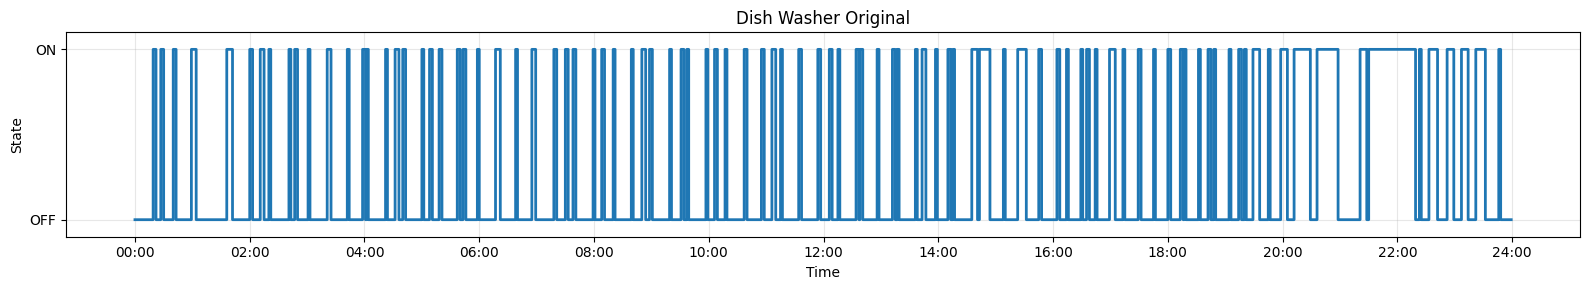

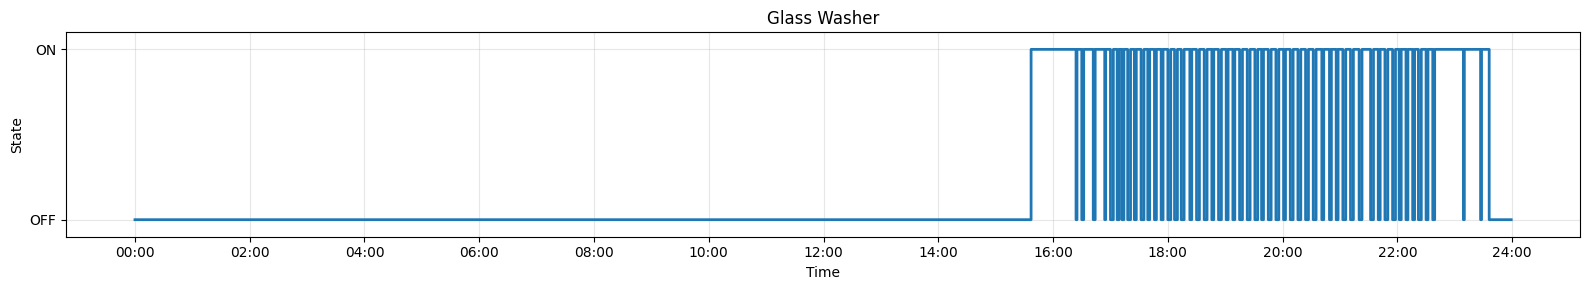

In [24]:
def plot_binary_profile_day(
    X_matrix,
    device_idx,
    device_name,
    figsize=(16, 3)
):

    minutes = np.arange(1440)

    plt.figure(figsize=figsize)

    plt.step(
        minutes,
        X_matrix[:, device_idx],
        where="post",
        linewidth=2
    )

    plt.yticks([0, 1], ["OFF", "ON"])

    xticks = np.arange(0, 1441, 120)

    plt.xticks(
        xticks,
        [f"{int(x//60):02d}:00" for x in xticks]
    )

    plt.ylim(-0.1, 1.1)

    plt.grid(True, alpha=0.3)

    plt.xlabel("Time")
    plt.ylabel("State")

    plt.title(device_name)

    plt.tight_layout()
    plt.show()
    
plot_binary_profile_day(
    X_onoff_FC_matrix,
    8,
    "Dish Washer Original"
)

plot_binary_profile_day(
    X_onoff_FC_matrix,
    7,
    "Glass Washer"
)

In [ ]:
# ======================================
# LEITURA DO INFO.XLSX
# ======================================

df_info = pd.read_excel('/Users/luismartins/Desktop/Tese/NexIK_Flexibility/Forecast_24h/RT24 Min Energy Consumption/Info_RT24.xlsx')

print("Colunas do Info.xlsx:")
print(df_info.columns.tolist())

# se quiseres confirmar o número de equipamentos do Excel
print("\nNúmero de linhas no Info.xlsx:", len(df_info))

# opcional: garantir consistência
if len(df_info) != N_DEV:
    raise ValueError(f"N_DEV={N_DEV}, mas o Info.xlsx tem {len(df_info)} linhas.")

# parâmetros por equipamento
dev_names = df_info["Dev"].tolist()

# índice do tipo de flexibilidade
Type = df_info["Type"].to_numpy(dtype=int)

# estado inicial
# para já vamos ler do Excel; mais tarde podes forçar a zero ou atualizar dinamicamente
State_Init = df_info["State_Init"].to_numpy(dtype=int)

# potência máxima
Power_max = df_info["Power_max"].to_numpy(dtype=float)

# pesos da componente de potência
Weight_P_max = df_info["Weight_P_max"].to_numpy(dtype=float)
Weight_P_min = df_info["Weight_P_min"].to_numpy(dtype=float)

# percentagens de potência
# MUITO IMPORTANTE: converter de % para fração
Y_max = df_info["Y_max (%)"].to_numpy(dtype=float) / 100.0
Y_min = df_info["Y_min (%)"].to_numpy(dtype=float) / 100.0

# tempo mínimo para manter alteração de potência
TimeHoldPower = df_info["TimeHoldPower"].to_numpy(dtype=float)

# impressão de controlo
print("\nResumo dos equipamentos:")
for j in range(N_DEV):
    print(
        f"{j}: {dev_names[j]} | "
        f"Type={Type[j]} | "
        f"State_Init={State_Init[j]} | "
        f"Pmax={Power_max[j]} | "
        f"Ymin={Y_min[j]} | "
        f"Ymax={Y_max[j]}"
        f" | TimeHoldPower={TimeHoldPower[j]}"
    )

FileNotFoundError: [Errno 2] No such file or directory: '/Users/luismartins/Desktop/Tese/NexIK_Flexibility/Forecast_24h/RT24 Min Energy Consumption/Info_RT24.xlsx'

# Optimization

In [17]:
T = 24 * 60

# =====================================================
# 1) BASELINE
# operação normal do restaurante / forecast original
# =====================================================
X_baseline_matrix = np.zeros((T, N_DEV), dtype=int)
Y_baseline_matrix = np.ones((T, N_DEV), dtype=float)
W_baseline_matrix = np.zeros((T, N_DEV), dtype=float)
P_baseline_matrix = np.zeros((T, N_DEV), dtype=float)
P_baseline_sum = np.zeros(T, dtype=float)


# =====================================================
# 2) BEFORE OPT RT
# estado real-time depois da function_dataset,
# antes de entrar no solver
# =====================================================
X_before_opt_rt_matrix = np.zeros((T, N_DEV), dtype=int)
Y_before_opt_rt_matrix = np.ones((T, N_DEV), dtype=float)
W_before_opt_rt_matrix = np.zeros((T, N_DEV), dtype=float)
P_before_opt_rt_matrix = np.zeros((T, N_DEV), dtype=float)
P_before_opt_rt_sum = np.zeros(T, dtype=float)

force_on_before_opt_rt_matrix = np.zeros((T, N_DEV), dtype=int)


# =====================================================
# 3) OPT RT
# resultado final aplicado depois da otimização
# se não houver otimização, é igual ao before_opt_rt
# =====================================================
X_opt_rt_matrix = np.zeros((T, N_DEV), dtype=int)
Y_opt_rt_matrix = np.ones((T, N_DEV), dtype=float)
W_opt_rt_matrix = np.zeros((T, N_DEV), dtype=float)
P_opt_rt_matrix = np.zeros((T, N_DEV), dtype=float)
P_opt_rt_sum = np.zeros(T, dtype=float)

force_on_opt_rt_matrix = np.zeros((T, N_DEV), dtype=int)


# =====================================================
# 4) Optimization metadata
# =====================================================
P_lim_vector = np.zeros(T, dtype=float)
P_rlx_vector = np.zeros(T, dtype=float)
Optimization_flag = np.zeros(T, dtype=int)

count_T_Hold_Power_matrix = np.zeros((T, N_DEV), dtype=int)


# =====================================================
# 5) Working vectors
# =====================================================
X_baseline_vector = np.zeros(N_DEV, dtype=int)
Y_baseline_vector = np.ones(N_DEV, dtype=float)
W_baseline_vector = np.zeros(N_DEV, dtype=float)
P_baseline_vector = np.zeros(N_DEV, dtype=float)

X_before_opt_rt_vector = np.zeros(N_DEV, dtype=int)
Y_before_opt_rt_vector = np.ones(N_DEV, dtype=float)
W_before_opt_rt_vector = np.zeros(N_DEV, dtype=float)
P_before_opt_rt_vector = np.zeros(N_DEV, dtype=float)

X_opt_rt_vector = np.zeros(N_DEV, dtype=int)
Y_opt_rt_vector = np.ones(N_DEV, dtype=float)
W_opt_rt_vector = np.zeros(N_DEV, dtype=float)
P_opt_rt_vector = np.zeros(N_DEV, dtype=float)

force_on_before_opt_rt_vector = np.zeros(N_DEV, dtype=int)
force_on_opt_rt_vector = np.zeros(N_DEV, dtype=int)

count_T_Hold_Power_vector = np.zeros(N_DEV, dtype=int)



W_P_before_opt_rt_matrix = np.zeros((T, N_DEV))
W_P_opt_rt_matrix = np.zeros((T, N_DEV))
W_P_baseline_matrix = np.zeros((T, N_DEV), dtype=float)

In [18]:
def function_dataset(i, X_RT_matrix, W_RT_matrix, X_aux, Type, variable_hysteresis=False):

    X_RT_vector = X_aux[i, :].copy()

    for j in range(len(Type)):

        if Type[j] == 2:

            if i != 0:
                X_RT_vector[j] = X_RT_matrix[i-1, j]

                if X_RT_matrix[i-1, j] == 1 and W_RT_matrix[i-1, j] <= 1:
                    X_RT_vector[j] = 0

                elif (
                    X_RT_matrix[i-1, j] == 0
                    and W_RT_matrix[i-1, j] >= get_w_max(j, i, variable_hysteresis)
                ):
                    X_RT_vector[j] = 1

        elif Type[j] in [0, 1]:
            X_RT_vector[j] = X_aux[i, j]

    return X_RT_vector

def initialize_weights_from_state(X0, Type):
    """
    Initialize time-component weights at t = 0.

    Rules
    -----
    Type == 2 (time-flexible):
        X = 1 -> W = 10
        X = 0 -> W = 1

    Other types:
        W = 10
    """
    W0 = np.zeros(len(X0), dtype=float)

    for j in range(len(X0)):
        if Type[j] == 2:
            if X0[j] == 1:
                W0[j] = 10.0
            else:
                W0[j] = 1.0
        else:
            W0[j] = 10.0

    return np.round(W0, 3)

def compute_power_vector(X_vec, Power_max, Y_vec):
    """
    Compute device power vector.

    P[j] = Power_max[j] * Y[j] * X[j]
    """
    return Power_max * Y_vec * X_vec

def compute_power_sum(P_vec):
    """
    Total power at the current minute.
    """
    return float(np.sum(P_vec))

def update_weights_and_flags(
    prev_W,
    X_now,
    Type,
    T_ON_now,
    T_OFF_now,
    minute,
    variable_hysteresis=False
):
    n = len(X_now)
    W_new = np.zeros(n, dtype=float)
    force_on_flag = np.zeros(n, dtype=int)

    for j in range(n):

        if Type[j] != 2:
            W_new[j] = 10.0
            force_on_flag[j] = 0
            continue

        W_max_now = get_w_max(j, minute, variable_hysteresis)

        if X_now[j] == 1:
            raw_w = prev_W[j] - 9.0 / max(T_ON_now[j], 1)
            W_new[j] = max(1.0, raw_w)
            force_on_flag[j] = 0

        else:
            raw_w = prev_W[j] + 9.0 / max(T_OFF_now[j], 1)

            if raw_w >= W_max_now:
                W_new[j] = W_max_now
                force_on_flag[j] = 1
            else:
                W_new[j] = raw_w
                force_on_flag[j] = 0

    return np.round(W_new, 3), force_on_flag

def get_p_lim_for_minute(minute):
    tz = get_time_zone(minute)

    if tz == 0:
        return 5000.0
    elif tz == 1:
        return 15000.0
    elif tz == 2:
        return 25000.0
    else:
        return 10000.0
def update_power_before_optimization(
    X_before_opt_rt_vector,
    Y_prev_opt_rt_vector,
    count_prev_vector,
    Type,
    Y_min
):
    Y_before_opt_rt_vector = Y_prev_opt_rt_vector.copy()
    count_vector = count_prev_vector.copy()

    for j in range(len(Type)):

        if X_before_opt_rt_vector[j] == 0:
            Y_before_opt_rt_vector[j] = 1.0
            count_vector[j] = 0

        elif Type[j] == 1:

            if count_vector[j] > 0:
                count_vector[j] -= 1

            # se count == 0, não faz nada:
            # mantém o Y anterior, mas o solver fica livre

        else:
            Y_before_opt_rt_vector[j] = 1.0
            count_vector[j] = 0

    return Y_before_opt_rt_vector, count_vector

def update_power_hold_after_optimization(
    X_opt_rt_vector,
    Y_before_opt_rt_vector,
    Y_opt_rt_vector,
    
    count_vector,
    Type,
    TimeHoldPower,
):
    count_updated = count_vector.copy()

    for j in range(len(Type)):

        if Type[j] == 1 and X_opt_rt_vector[j] == 1:

            if abs(Y_opt_rt_vector[j] - Y_before_opt_rt_vector[j]) > 1e-6:
                count_updated[j] = int(TimeHoldPower[j])

        else:
            count_updated[j] = 0

    return count_updated
def compute_wp_vector(Y_vec, Weight_P_min, Weight_P_max, Y_min, Y_max):

    epsilon = 1e-4

    return (
        Weight_P_min
        +
        (
            (Weight_P_max - Weight_P_min)
            /
            (Y_max - Y_min + epsilon)
        )
        * (Y_vec - Y_min)
    )

def get_w_max(j, minute, variable_hysteresis=False):
    if variable_hysteresis:
        tz = get_time_zone(minute)
        if j == 0 and tz == 1:
            return 17.0
    return 10.0

In [49]:
m = pe.ConcreteModel()

# =========================
# Sets
# =========================
m.J = pe.RangeSet(0, N_DEV - 1)

# =========================
# Fixed parameters
# =========================
m.Type = pe.Param(m.J, initialize={j: int(Type[j]) for j in range(N_DEV)})
m.P_max = pe.Param(m.J, initialize={j: float(Power_max[j]) for j in range(N_DEV)})

m.Y_min = pe.Param(m.J, initialize={j: float(Y_min[j]) for j in range(N_DEV)})
m.Y_max = pe.Param(m.J, initialize={j: float(Y_max[j]) for j in range(N_DEV)})

m.W_P_min = pe.Param(m.J, initialize={j: float(Weight_P_min[j]) for j in range(N_DEV)})
m.W_P_max = pe.Param(m.J, initialize={j: float(Weight_P_max[j]) for j in range(N_DEV)})

m.T_Hold_Power = pe.Param(
    m.J,
    initialize={j: float(TimeHoldPower[j]) for j in range(N_DEV)}
)

# =========================
# Mutable RT parameters
# updated each minute
# =========================
m.P_lim = pe.Param(initialize=0.0, mutable=True)

m.X_in = pe.Param(m.J, initialize=0, mutable=True)
m.X_prev = pe.Param(m.J, initialize=0, mutable=True)

m.W_time = pe.Param(m.J, initialize=0.0, mutable=True)

# Y actual antes da otimização
m.Y_in = pe.Param(m.J, initialize={j: float(Y_min[j]) for j in range(N_DEV)}, mutable=True)

# contador do tempo que falta / já passou desde alteração de potência
m.count_T_Hold_Power = pe.Param(m.J, initialize=0, mutable=True)

m.force_on = pe.Param(m.J, initialize=0, mutable=True)

# =========================
# Decision variables
# =========================
m.X_opt = pe.Var(m.J, domain=pe.Binary)
m.Y_opt = pe.Var(m.J, domain=pe.NonNegativeReals)
m.P_rlx = pe.Var(domain=pe.NonNegativeReals)

# =========================
# Constraints
# =========================
# Total power constraint
def power_limit_rule(m):
    return sum(
        m.P_max[j] * m.X_opt[j] * m.Y_opt[j]
        for j in m.J
    ) <= m.P_lim + m.P_rlx

m.power_limit = pe.Constraint(rule=power_limit_rule)


# Y lower bound
def y_min_rule(m, j):
    return m.Y_opt[j] >= m.Y_min[j]

m.y_min_constraint = pe.Constraint(m.J, rule=y_min_rule)


# Y upper bound
def y_max_rule(m, j):
    return m.Y_opt[j] <= m.Y_max[j]

m.y_max_constraint = pe.Constraint(m.J, rule=y_max_rule)

# ---------------------------
# Constraint 2:
# Status logic by flexibility type
#
# Type 0 = non-flexible  -> X_opt = X_in
# Type 1 = power-flexible -> X_opt = X_in
# Type 2 = time-flexible  -> X_opt <= X_in
#
# If W_time == -1, force reconnection: X_opt = X_in
# ---------------------------
def status_logic_rule(m, j):

    # Non-flexible e power-flexible mantêm estado
    if pe.value(m.Type[j]) in [0, 1]:
        return m.X_opt[j] == m.X_in[j]

    # Time-flexible
    if pe.value(m.Type[j]) == 2:

        # Se está forçado por limite térmico, tem mesmo de ficar ON
        if pe.value(m.force_on[j]) == 1:
            return m.X_opt[j] == 1

        # caso contrário, pode ser desligado
        return m.X_opt[j] <= m.X_in[j]

    return pe.Constraint.Feasible

m.status_logic = pe.Constraint(m.J, rule=status_logic_rule)

def power_hold_rule(m, j):
    # se não for power-flexible, mantém Y = Y_in
    if pe.value(m.Type[j]) != 1:
        return m.Y_opt[j] == m.Y_in[j]

    # se ainda está dentro do T_Hold_Power, mantém o Y anterior
    if pe.value(m.count_T_Hold_Power[j]) != 0:
        return m.Y_opt[j] == m.Y_in[j]

    # caso contrário, pode otimizar Y dentro de [Y_min, Y_max]
    return pe.Constraint.Feasible

def min_energy_y_rule(m, j):
    if pe.value(m.Type[j]) == 1 and pe.value(m.X_in[j]) == 1:
        return m.Y_opt[j] == m.Y_min[j]

    return pe.Constraint.Feasible

m.min_energy_y_constraint = pe.Constraint(m.J, rule=min_energy_y_rule)

m.power_hold_constraint = pe.Constraint(m.J, rule=power_hold_rule)

alpha_comfort = 600
penalty_rlx = 10000

def objective_rule(m):

    energy_term = sum(
        m.P_max[j] * m.X_opt[j] * m.Y_opt[j]
        for j in m.J
    )

    thermal_loss_term = sum(
        alpha_comfort
        * m.W_time[j]
        * (m.X_in[j] - m.X_opt[j])
        for j in m.J
        if pe.value(m.Type[j]) == 2
    )

    return energy_term + thermal_loss_term + penalty_rlx * m.P_rlx
m.objective = pe.Objective(rule=objective_rule, sense=pe.minimize)

In [50]:
solver = pe.SolverFactory('scip')
variable_hysteresis = False

for i in range(T):

    P_lim = get_p_lim_for_minute(i)

    T_ON_now = T_ON_FC_matrix[i, :].copy()
    T_OFF_now = T_OFF_FC_matrix[i, :].copy()

    # =====================================================
    # i = 0 initialization
    # =====================================================
    if i == 0:

        # ---------- baseline ----------
        X_baseline_vector = X_onoff_FC_matrix[i, :].copy()
        Y_baseline_vector = np.ones(N_DEV)

        P_baseline_vector = compute_power_vector(
            X_baseline_vector, Power_max, Y_baseline_vector
        )

        W_baseline_vector = initialize_weights_from_state(
            X_baseline_vector, Type
        )

        W_P_baseline_vector = compute_wp_vector(
            Y_baseline_vector,
            Weight_P_min,
            Weight_P_max,
            Y_min,
            Y_max
        )

        # ---------- before opt RT ----------
        X_before_opt_rt_vector = X_baseline_vector.copy()
        Y_before_opt_rt_vector = Y_baseline_vector.copy()
        W_before_opt_rt_vector = W_baseline_vector.copy()

        force_on_before_opt_rt_vector = np.zeros(N_DEV, dtype=int)

        for j in range(N_DEV):
            if Type[j] == 1 and X_before_opt_rt_vector[j] == 1:
                Y_before_opt_rt_vector[j] = Y_min[j]

        P_before_opt_rt_vector = compute_power_vector(
            X_before_opt_rt_vector,
            Power_max,
            Y_before_opt_rt_vector
        )

        W_P_before_opt_rt_vector = compute_wp_vector(
            Y_before_opt_rt_vector,
            Weight_P_min,
            Weight_P_max,
            Y_min,
            Y_max
        )

        # ---------- opt RT ----------
        X_opt_rt_vector = X_before_opt_rt_vector.copy()
        Y_opt_rt_vector = Y_before_opt_rt_vector.copy()
        W_opt_rt_vector = W_before_opt_rt_vector.copy()
        P_opt_rt_vector = P_before_opt_rt_vector.copy()

        force_on_opt_rt_vector = np.zeros(N_DEV, dtype=int)
        count_T_Hold_Power_vector = np.zeros(N_DEV, dtype=int)

        W_P_opt_rt_vector = compute_wp_vector(
            Y_opt_rt_vector,
            Weight_P_min,
            Weight_P_max,
            Y_min,
            Y_max
        )

        # ---------- store baseline ----------
        X_baseline_matrix[i, :] = X_baseline_vector.copy()
        Y_baseline_matrix[i, :] = Y_baseline_vector.copy()
        W_baseline_matrix[i, :] = W_baseline_vector.copy()
        P_baseline_matrix[i, :] = P_baseline_vector.copy()
        P_baseline_sum[i] = compute_power_sum(P_baseline_vector)
        W_P_baseline_matrix[i, :] = W_P_baseline_vector.copy()

        # ---------- store before opt RT ----------
        X_before_opt_rt_matrix[i, :] = X_before_opt_rt_vector.copy()
        Y_before_opt_rt_matrix[i, :] = Y_before_opt_rt_vector.copy()
        W_before_opt_rt_matrix[i, :] = W_before_opt_rt_vector.copy()
        P_before_opt_rt_matrix[i, :] = P_before_opt_rt_vector.copy()
        P_before_opt_rt_sum[i] = compute_power_sum(P_before_opt_rt_vector)
        force_on_before_opt_rt_matrix[i, :] = force_on_before_opt_rt_vector.copy()
        W_P_before_opt_rt_matrix[i, :] = W_P_before_opt_rt_vector.copy()

        # ---------- store opt RT ----------
        X_opt_rt_matrix[i, :] = X_opt_rt_vector.copy()
        Y_opt_rt_matrix[i, :] = Y_opt_rt_vector.copy()
        W_opt_rt_matrix[i, :] = W_opt_rt_vector.copy()
        P_opt_rt_matrix[i, :] = P_opt_rt_vector.copy()
        P_opt_rt_sum[i] = compute_power_sum(P_opt_rt_vector)
        force_on_opt_rt_matrix[i, :] = force_on_opt_rt_vector.copy()
        count_T_Hold_Power_matrix[i, :] = count_T_Hold_Power_vector.copy()
        W_P_opt_rt_matrix[i, :] = W_P_opt_rt_vector.copy()

        # ---------- metadata ----------
        P_lim_vector[i] = P_lim
        P_rlx_vector[i] = 0.0
        Optimization_flag[i] = 0

    # =====================================================
    # normal cycle
    # =====================================================
    else:

        # =================================================
        # 1) BASELINE
        # =================================================
        X_baseline_vector = X_onoff_FC_matrix[i, :].copy()
        Y_baseline_vector = np.ones(N_DEV)

        P_baseline_vector = compute_power_vector(
            X_baseline_vector,
            Power_max,
            Y_baseline_vector
        )

        W_baseline_vector, _ = update_weights_and_flags(
            prev_W=W_baseline_matrix[i-1, :].copy(),
            X_now=X_baseline_vector,
            Type=Type,
            T_ON_now=T_ON_now,
            T_OFF_now=T_OFF_now,
            minute=i,
            variable_hysteresis=variable_hysteresis
        )

        W_P_baseline_vector = compute_wp_vector(
            Y_baseline_vector,
            Weight_P_min,
            Weight_P_max,
            Y_min,
            Y_max
        )

        X_baseline_matrix[i, :] = X_baseline_vector.copy()
        Y_baseline_matrix[i, :] = Y_baseline_vector.copy()
        W_baseline_matrix[i, :] = W_baseline_vector.copy()
        P_baseline_matrix[i, :] = P_baseline_vector.copy()
        P_baseline_sum[i] = compute_power_sum(P_baseline_vector)
        W_P_baseline_matrix[i, :] = W_P_baseline_vector.copy()

        # =================================================
        # 2) BEFORE OPT RT
        # =================================================
        X_before_opt_rt_vector = function_dataset(
            i=i,
            X_RT_matrix=X_opt_rt_matrix,
            W_RT_matrix=W_opt_rt_matrix,
            X_aux=X_onoff_FC_matrix,
            Type=Type,
            variable_hysteresis=variable_hysteresis
        )

        Y_before_opt_rt_vector, count_T_Hold_Power_vector = update_power_before_optimization(
            X_before_opt_rt_vector=X_before_opt_rt_vector,
            Y_prev_opt_rt_vector=Y_opt_rt_matrix[i-1, :],
            count_prev_vector=count_T_Hold_Power_matrix[i-1, :],
            Type=Type,
            Y_min=Y_min
        )

        W_P_before_opt_rt_vector = compute_wp_vector(
            Y_before_opt_rt_vector,
            Weight_P_min,
            Weight_P_max,
            Y_min,
            Y_max
        )

        P_before_opt_rt_vector = compute_power_vector(
            X_before_opt_rt_vector,
            Power_max,
            Y_before_opt_rt_vector
        )

        P_before_opt_rt_sum[i] = compute_power_sum(P_before_opt_rt_vector)

        W_before_opt_rt_vector, force_on_before_opt_rt_vector = update_weights_and_flags(
            prev_W=W_opt_rt_matrix[i-1, :].copy(),
            X_now=X_before_opt_rt_vector,
            Type=Type,
            T_ON_now=T_ON_now,
            T_OFF_now=T_OFF_now,
            minute=i,
            variable_hysteresis=variable_hysteresis
        )

        X_before_opt_rt_matrix[i, :] = X_before_opt_rt_vector.copy()
        Y_before_opt_rt_matrix[i, :] = Y_before_opt_rt_vector.copy()
        W_before_opt_rt_matrix[i, :] = W_before_opt_rt_vector.copy()
        P_before_opt_rt_matrix[i, :] = P_before_opt_rt_vector.copy()
        force_on_before_opt_rt_matrix[i, :] = force_on_before_opt_rt_vector.copy()
        W_P_before_opt_rt_matrix[i, :] = W_P_before_opt_rt_vector.copy()

        # default: sem otimização, final = before opt
        X_opt_rt_vector = X_before_opt_rt_vector.copy()
        Y_opt_rt_vector = Y_before_opt_rt_vector.copy()
        W_opt_rt_vector = W_before_opt_rt_vector.copy()
        P_opt_rt_vector = P_before_opt_rt_vector.copy()
        force_on_opt_rt_vector = force_on_before_opt_rt_vector.copy()

        count_T_Hold_Power_vector = update_power_hold_after_optimization(
            X_opt_rt_vector=X_opt_rt_vector,
            Y_before_opt_rt_vector=Y_before_opt_rt_vector,
            Y_opt_rt_vector=Y_opt_rt_vector,
            count_vector=count_T_Hold_Power_vector,
            Type=Type,
            TimeHoldPower=TimeHoldPower
        )

        W_P_opt_rt_vector = compute_wp_vector(
            Y_opt_rt_vector,
            Weight_P_min,
            Weight_P_max,
            Y_min,
            Y_max
        )

        P_lim_vector[i] = P_lim
        P_rlx_vector[i] = 0.0
        Optimization_flag[i] = 0

        # =================================================
        # 3) OPTIMIZATION
        # =================================================
        if P_before_opt_rt_sum[i] > P_lim:

            Optimization_flag[i] = 1
            m.P_lim.set_value(float(P_lim))

            for j in range(N_DEV):

                m.W_time[j] = float(W_before_opt_rt_vector[j])

                m.X_in[j] = int(X_before_opt_rt_vector[j])
                m.X_prev[j] = int(X_opt_rt_matrix[i-1, j])
                m.force_on[j] = int(force_on_before_opt_rt_vector[j])

                m.Y_in[j] = float(Y_before_opt_rt_vector[j])
                m.count_T_Hold_Power[j] = int(count_T_Hold_Power_vector[j])

                m.X_opt[j].value = int(X_before_opt_rt_vector[j])
                m.Y_opt[j].value = float(Y_before_opt_rt_vector[j])

            m.P_rlx.value = 0.0

            if hasattr(m, 'status_logic'):
                m.del_component(m.status_logic)

            if hasattr(m, 'power_hold_constraint'):
                m.del_component(m.power_hold_constraint)

            if hasattr(m, 'min_energy_y_constraint'):
                m.del_component(m.min_energy_y_constraint)

            m.status_logic = pe.Constraint(m.J, rule=status_logic_rule)
            m.power_hold_constraint = pe.Constraint(m.J, rule=power_hold_rule)
            m.min_energy_y_constraint = pe.Constraint(m.J, rule=min_energy_y_rule)

            results = solver.solve(m, tee=False)

            for j in range(N_DEV):

                X_opt_rt_vector[j] = int(round(pe.value(m.X_opt[j])))

                if X_opt_rt_vector[j] == 1:
                    Y_opt_rt_vector[j] = float(pe.value(m.Y_opt[j]))
                else:
                    Y_opt_rt_vector[j] = 1.0

            count_T_Hold_Power_vector = update_power_hold_after_optimization(
                X_opt_rt_vector=X_opt_rt_vector,
                Y_before_opt_rt_vector=Y_before_opt_rt_vector,
                Y_opt_rt_vector=Y_opt_rt_vector,
                count_vector=count_T_Hold_Power_vector,
                Type=Type,
                TimeHoldPower=TimeHoldPower
            )

            W_P_opt_rt_vector = compute_wp_vector(
                Y_opt_rt_vector,
                Weight_P_min,
                Weight_P_max,
                Y_min,
                Y_max
            )

            P_rlx_vector[i] = float(pe.value(m.P_rlx))

            P_opt_rt_vector = compute_power_vector(
                X_opt_rt_vector,
                Power_max,
                Y_opt_rt_vector
            )

            P_opt_rt_sum[i] = compute_power_sum(P_opt_rt_vector)

            W_opt_rt_vector, force_on_opt_rt_vector = update_weights_and_flags(
                prev_W=W_opt_rt_matrix[i-1, :].copy(),
                X_now=X_opt_rt_vector,
                Type=Type,
                T_ON_now=T_ON_now,
                T_OFF_now=T_OFF_now,
                minute=i,
                variable_hysteresis=variable_hysteresis
            )

        # =================================================
        # 4) STORE OPT RT
        # =================================================
        X_opt_rt_matrix[i, :] = X_opt_rt_vector.copy()
        Y_opt_rt_matrix[i, :] = Y_opt_rt_vector.copy()
        W_opt_rt_matrix[i, :] = W_opt_rt_vector.copy()
        P_opt_rt_matrix[i, :] = P_opt_rt_vector.copy()
        P_opt_rt_sum[i] = compute_power_sum(P_opt_rt_vector)

        force_on_opt_rt_matrix[i, :] = force_on_opt_rt_vector.copy()
        count_T_Hold_Power_matrix[i, :] = count_T_Hold_Power_vector.copy()
        W_P_opt_rt_matrix[i, :] = W_P_opt_rt_vector.copy()

    print(f"\n######################## Minute {i} ########################")
    print(f"Optimization needed       : {Optimization_flag[i]}")

    print(f"X baseline                : {X_baseline_matrix[i, :]}")
    print(f"W baseline                : {W_baseline_matrix[i, :]}")

    print(f"X before opt RT           : {X_before_opt_rt_matrix[i, :]}")
    print(f"Y before opt RT           : {Y_before_opt_rt_matrix[i, :]}")
    print(f"W before opt RT           : {W_before_opt_rt_matrix[i, :]}")

    print(f"X opt RT                  : {X_opt_rt_matrix[i, :]}")
    print(f"Y opt RT                  : {Y_opt_rt_matrix[i, :]}")
    print(f"W opt RT                  : {W_opt_rt_matrix[i, :]}")

    print(f"T_hold counter            : {count_T_Hold_Power_matrix[i, :]}")
    print(f"P baseline sum            : {P_baseline_sum[i]:.2f}")
    print(f"P before opt RT sum       : {P_before_opt_rt_sum[i]:.2f}")
    print(f"P opt RT sum              : {P_opt_rt_sum[i]:.2f}")
    print(f"P_rlx                     : {P_rlx_vector[i]:.2f}")


######################## Minute 0 ########################
Optimization needed       : 0
X baseline                : [0 0 0 1 0 0 0 0 0 0 0 0 0]
W baseline                : [ 1.  1.  1. 10.  1.  1.  1. 10. 10. 10. 10. 10. 10.]
X before opt RT           : [0 0 0 1 0 0 0 0 0 0 0 0 0]
Y before opt RT           : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
W before opt RT           : [ 1.  1.  1. 10.  1.  1.  1. 10. 10. 10. 10. 10. 10.]
X opt RT                  : [0 0 0 1 0 0 0 0 0 0 0 0 0]
Y opt RT                  : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
W opt RT                  : [ 1.  1.  1. 10.  1.  1.  1. 10. 10. 10. 10. 10. 10.]
T_hold counter            : [0 0 0 0 0 0 0 0 0 0 0 0 0]
P baseline sum            : 400.00
P before opt RT sum       : 400.00
P opt RT sum              : 400.00
P_rlx                     : 0.00

######################## Minute 1 ########################
Optimization needed       : 0
X baseline                : [0 0 0 1 0 0 0 0 0 0 0 0 0]
W baseline        

In [51]:
def build_power_cases(
    X_baseline_matrix,
    Y_baseline_matrix,

    X_before_opt_rt_matrix,
    Y_before_opt_rt_matrix,

    X_opt_rt_matrix,
    Y_opt_rt_matrix,

    Power_max,

    P_baseline_sum,
    P_before_opt_rt_sum,
    P_opt_rt_sum
):

    P_baseline_dev = (
        X_baseline_matrix
        * Y_baseline_matrix
        * Power_max.reshape(1, -1)
    )

    P_before_opt_rt_dev = (
        X_before_opt_rt_matrix
        * Y_before_opt_rt_matrix
        * Power_max.reshape(1, -1)
    )

    P_opt_rt_dev = (
        X_opt_rt_matrix
        * Y_opt_rt_matrix
        * Power_max.reshape(1, -1)
    )

    return {

        "Baseline": {
            "P_dev": P_baseline_dev,
            "P_total": P_baseline_sum,
        },

        "Before Opt RT": {
            "P_dev": P_before_opt_rt_dev,
            "P_total": P_before_opt_rt_sum,
        },

        "Optimized RT": {
            "P_dev": P_opt_rt_dev,
            "P_total": P_opt_rt_sum,
        },
    }
def get_interval(tz_start=0, tz_end=None):
    if tz_end is None:
        tz_end = 24 * 60

    minutes = np.arange(tz_start, tz_end)
    time_labels = [f"{m//60:02d}:{m%60:02d}" for m in minutes]

    return minutes, time_labels
def plot_stacked_power_case(
    case_name,
    P_dev,
    P_total,
    P_lim_vector,
    dev_names,
    colors,
    tz_start=0,
    tz_end=None,
    tick_step=60
):
    if tz_end is None:
        tz_end = len(P_total)

    minutes, time_labels = get_interval(tz_start, tz_end)

    P_dev_slice = P_dev[tz_start:tz_end, :]
    P_total_slice = P_total[tz_start:tz_end]
    P_lim_slice = P_lim_vector[tz_start:tz_end]

    fig, ax = plt.subplots(figsize=(16, 7))

    ax.stackplot(
        range(len(time_labels)),
        P_dev_slice.T,
        labels=dev_names,
        colors=colors[:len(dev_names)],
        alpha=0.95
    )

    ax.plot(range(len(time_labels)), P_lim_slice, "k--", lw=2, label="P_lim")
    ax.plot(range(len(time_labels)), P_total_slice, "k", lw=1.5, alpha=0.5, label=f"{case_name} Total")

    ax.set_ylabel("Power [W]", fontsize=14, fontweight="bold")
    ax.set_xlabel("Time", fontsize=14, fontweight="bold")
    ax.set_xticks(np.arange(0, len(time_labels), tick_step))
    ax.set_xticklabels(time_labels[::tick_step], rotation=90)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)

    plt.tight_layout()
    plt.show()
def compute_consumption_metrics(power_cases, tz_start=0, tz_end=None):
    if tz_end is None:
        first_case = next(iter(power_cases.values()))
        tz_end = len(first_case["P_total"])

    dt_h = 1 / 60
    rows = []

    for case_name, data in power_cases.items():
        P = data["P_total"][tz_start:tz_end]

        rows.append({
            "case": case_name,
            "energy_kWh": np.sum(P) * dt_h / 1000,
            "average_power_W": np.mean(P),
            "max_power_W": np.max(P),
        })

    return pd.DataFrame(rows)
def plot_consumption_metrics(consumption_df, title="Energy Consumption"):
    fig, ax = plt.subplots(figsize=(8, 5))

    ax.bar(consumption_df["case"], consumption_df["energy_kWh"])
    ax.set_ylabel("Energy [kWh]", fontsize=14, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
def compute_peak_metrics(power_cases, P_lim_vector, tz_start=0, tz_end=None):
    if tz_end is None:
        tz_end = len(P_lim_vector)

    P_lim_slice = P_lim_vector[tz_start:tz_end]
    dt_h = 1 / 60

    rows = []

    for case_name, data in power_cases.items():
        P = data["P_total"][tz_start:tz_end]

        violations = P > P_lim_slice
        excess_power = np.maximum(P - P_lim_slice, 0)

        rows.append({
            "case": case_name,
            "n_violations_min": int(np.sum(violations)),
            "violation_time_h": np.sum(violations) / 60,
            "max_power_W": np.max(P),
            "max_excess_W": np.max(excess_power),
            "mean_excess_when_violating_W": np.mean(excess_power[violations]) if np.any(violations) else 0,
            "total_excess_kWh": np.sum(excess_power) * dt_h / 1000,
        })

    df = pd.DataFrame(rows)

    baseline = df[df["case"] == "Baseline"].iloc[0]

    df["violation_reduction_vs_baseline_%"] = (
        100 * (baseline["n_violations_min"] - df["n_violations_min"]) / baseline["n_violations_min"]
        if baseline["n_violations_min"] > 0 else 0
    )

    df["excess_energy_reduction_vs_baseline_%"] = (
        100 * (baseline["total_excess_kWh"] - df["total_excess_kWh"]) / baseline["total_excess_kWh"]
        if baseline["total_excess_kWh"] > 0 else 0
    )

    df["peak_power_reduction_vs_baseline_%"] = (
        100 * (baseline["max_power_W"] - df["max_power_W"]) / baseline["max_power_W"]
        if baseline["max_power_W"] > 0 else 0
    )

    return df
def plot_peak_metrics(peak_df, title="Threshold Violations"):
    fig, ax = plt.subplots(figsize=(8, 5))

    ax.bar(peak_df["case"], peak_df["n_violations_min"])
    ax.set_ylabel("Minutes above threshold", fontsize=14, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
    
def compute_shifted_energy_metrics(power_cases, baseline_case="Baseline", tz_start=0, tz_end=None):
    if tz_end is None:
        first_case = next(iter(power_cases.values()))
        tz_end = len(first_case["P_total"])

    dt_h = 1 / 60

    baseline_power = power_cases[baseline_case]["P_total"][tz_start:tz_end]
    baseline_energy_kwh = np.sum(baseline_power) * dt_h / 1000

    rows = []

    for case_name, data in power_cases.items():
        P_case = data["P_total"][tz_start:tz_end]

        shifted_power_W = np.maximum(baseline_power - P_case, 0.0)
        shifted_energy_kWh = np.sum(shifted_power_W) * dt_h / 1000

        rows.append({
            "case": case_name,
            "shifted_energy_kWh": shifted_energy_kWh,
            "shifted_energy_pct_of_baseline": (
                100 * shifted_energy_kWh / baseline_energy_kwh
                if baseline_energy_kwh > 0 else 0.0
            ),
        })

    return pd.DataFrame(rows)
def plot_shifted_energy_metrics(shifted_df, title="Shifted Energy"):
    fig, ax = plt.subplots(figsize=(8, 5))

    ax.bar(shifted_df["case"], shifted_df["shifted_energy_kWh"])
    ax.set_ylabel("Shifted Energy [kWh]", fontsize=14, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


colors = [
    "#4F81BD",  # Drinks Refrigerator
    "#C0504D",  # Blast Chiller
    "#9BBB59",  # Garde Manger
    "#8064A2",  # Ice Machine
    "#4BACC6",  # Dual Fryer
    "#F79646",  # Salamander
    "#385D8A",  # Infrared Shelf
    "#943634",  # Glass Washer
    "#76923C",  # Dish Washer
    "#5F497A",  # Convection Oven
    "#FFD700",  # Light1
    "#EEFF00",  # Light2
    "#708090",  # Exhaust
    
]

power_cases = build_power_cases(
    X_baseline_matrix=X_baseline_matrix,
    Y_baseline_matrix=Y_baseline_matrix,

    X_before_opt_rt_matrix=X_before_opt_rt_matrix,
    Y_before_opt_rt_matrix=Y_before_opt_rt_matrix,

    X_opt_rt_matrix=X_opt_rt_matrix,
    Y_opt_rt_matrix=Y_opt_rt_matrix,

    Power_max=Power_max,

    P_baseline_sum=P_baseline_sum,
    P_before_opt_rt_sum=P_before_opt_rt_sum,
    P_opt_rt_sum=P_opt_rt_sum
)

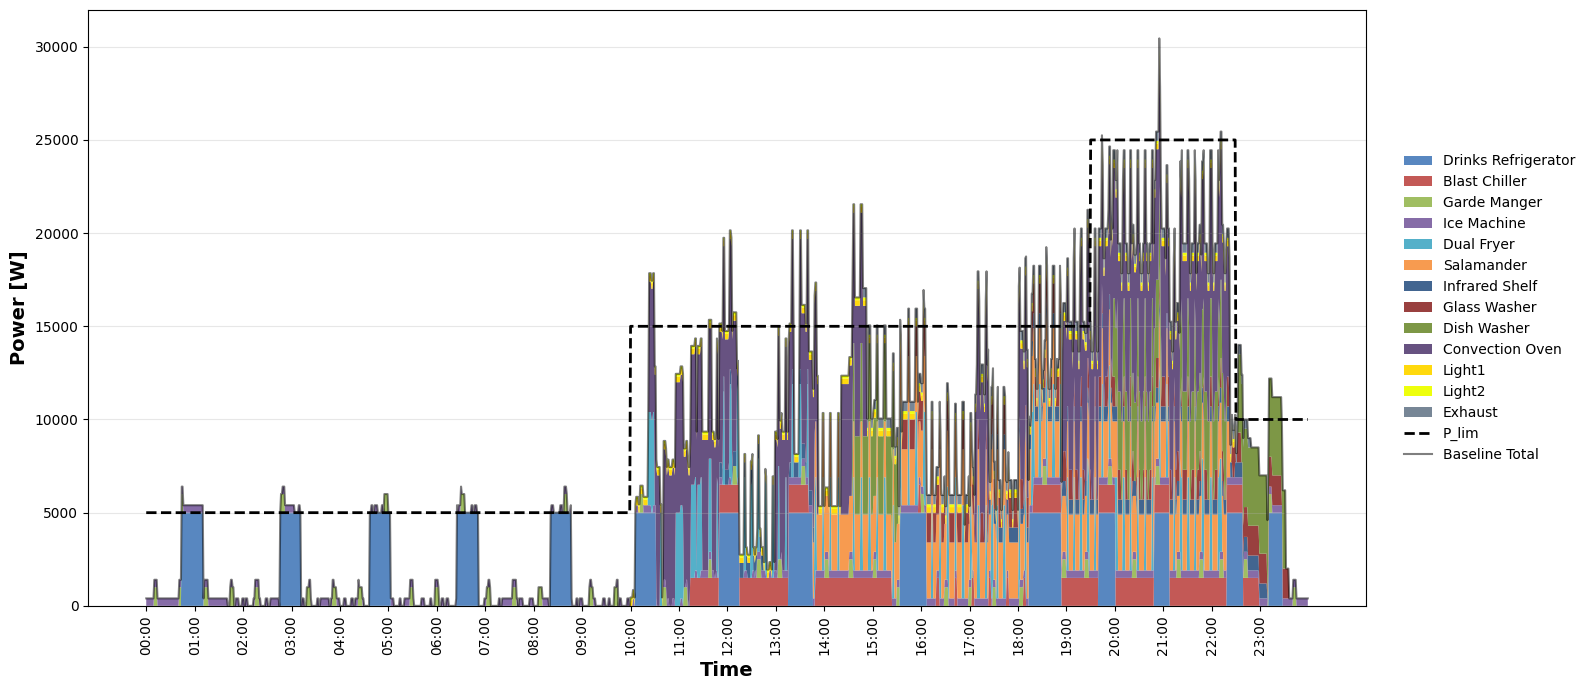

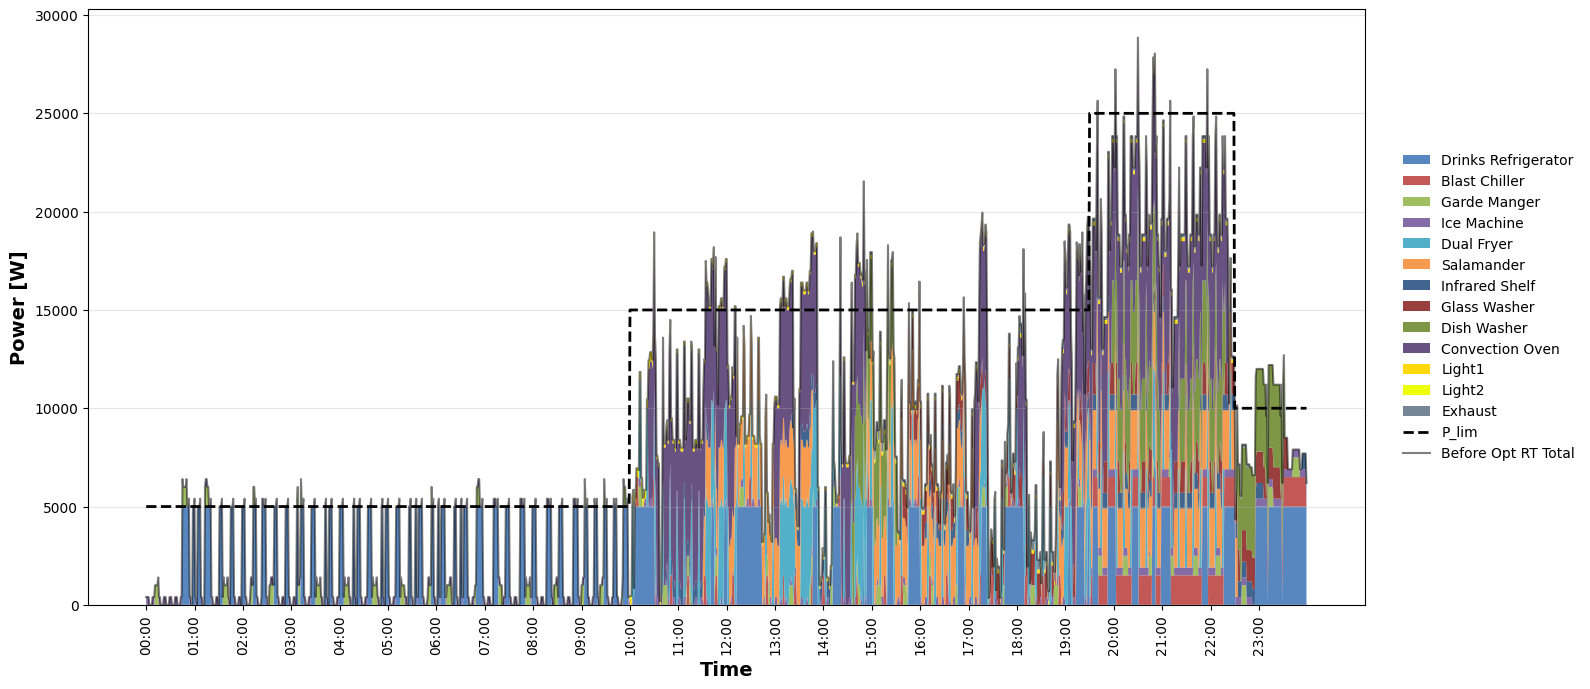

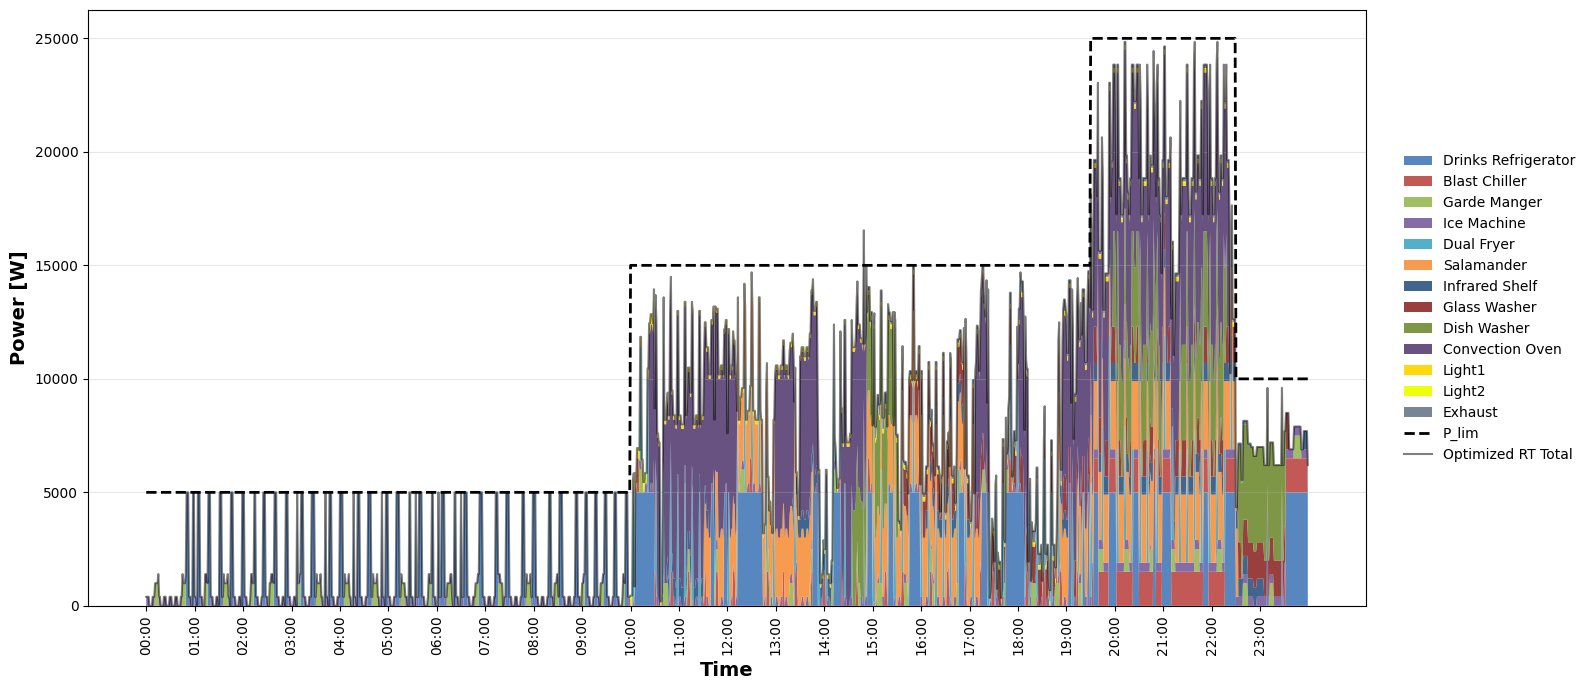


Energy Consumption Metrics:


,case,energy_kWh,average_power_W,max_power_W
0,Baseline,187.793333,7824.722222,30450.0
1,Before Opt RT,187.289250,7803.718750,28845.0
2,Optimized RT,166.168333,6923.680556,24845.0



Peak / Threshold Violation Metrics:


,case,n_violations_min,violation_time_h,max_power_W,max_excess_W,mean_excess_when_violating_W,total_excess_kWh,violation_reduction_vs_baseline_%,excess_energy_reduction_vs_baseline_%,peak_power_reduction_vs_baseline_%
0,Baseline,247,4.116667,30450.0,6550.0,1567.004049,6.450833,0.000000,0.000000,0.000000
1,Before Opt RT,252,4.200000,28845.0,6545.0,1550.753968,6.513167,-2.024291,-0.966283,5.270936
2,Optimized RT,1,0.016667,24845.0,1545.0,1545.000000,0.025750,99.595142,99.600827,18.407225



Shifted Energy vs Baseline:


,case,shifted_energy_kWh,shifted_energy_pct_of_baseline
0,Baseline,0.000000,0.000000
1,Before Opt RT,38.065250,20.269756
2,Optimized RT,47.311083,25.193164


In [52]:
tz_start = 0
tz_end = 24 * 60

for case_name, data in power_cases.items():
    plot_stacked_power_case(
        case_name=case_name,
        P_dev=data["P_dev"],
        P_total=data["P_total"],
        P_lim_vector=P_lim_vector,
        dev_names=dev_names,
        colors=colors,
        tz_start=tz_start,
        tz_end=tz_end,
        tick_step=60
    )

consumption_24h_df = compute_consumption_metrics(
    power_cases,
    tz_start=tz_start,
    tz_end=tz_end
)
print("\nEnergy Consumption Metrics:")
display(consumption_24h_df)
peak_24h_df = compute_peak_metrics(
    power_cases,
    P_lim_vector,
    tz_start=tz_start,
    tz_end=tz_end
)
print("\nPeak / Threshold Violation Metrics:")
display(peak_24h_df)
shifted_24h_df = compute_shifted_energy_metrics(
    power_cases,
    baseline_case="Baseline",
    tz_start=tz_start,
    tz_end=tz_end
)
print("\nShifted Energy vs Baseline:")
display(shifted_24h_df)


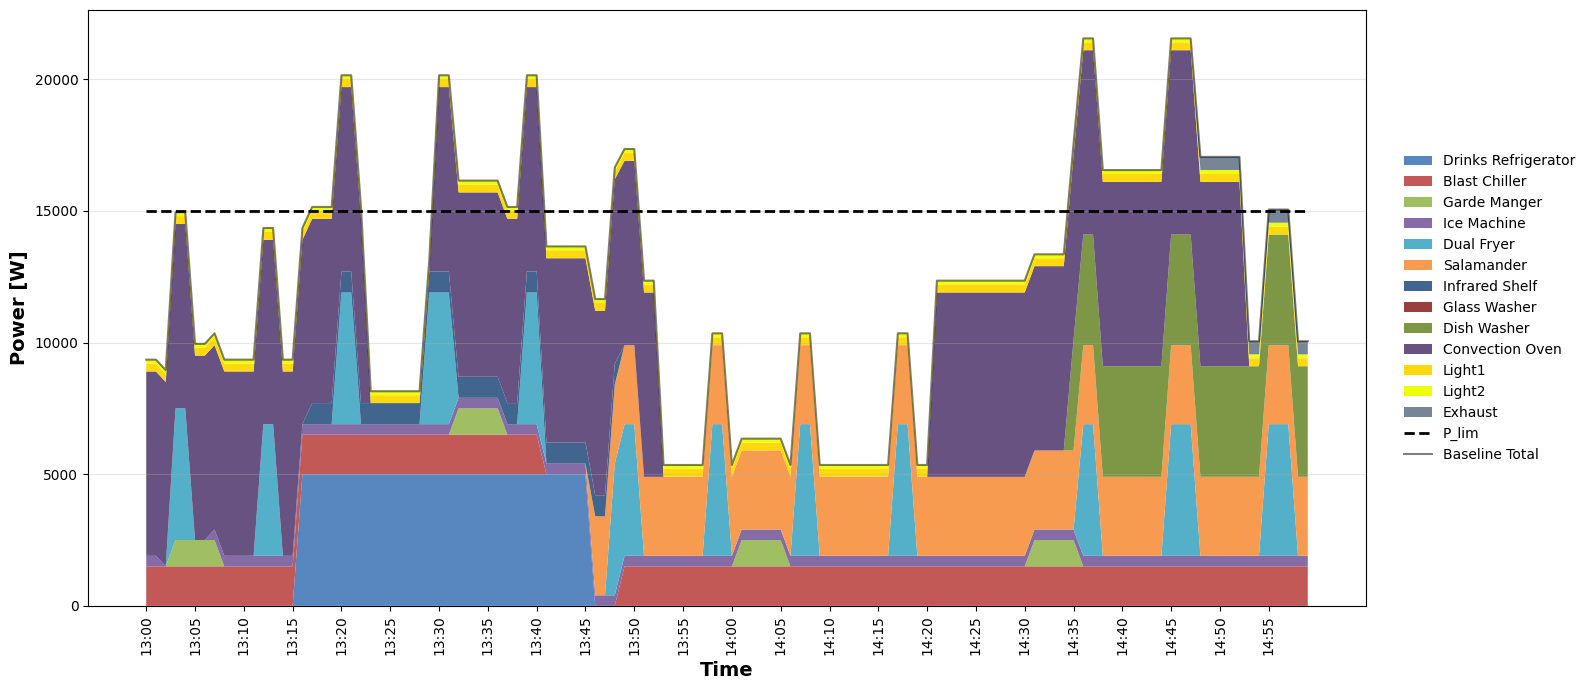

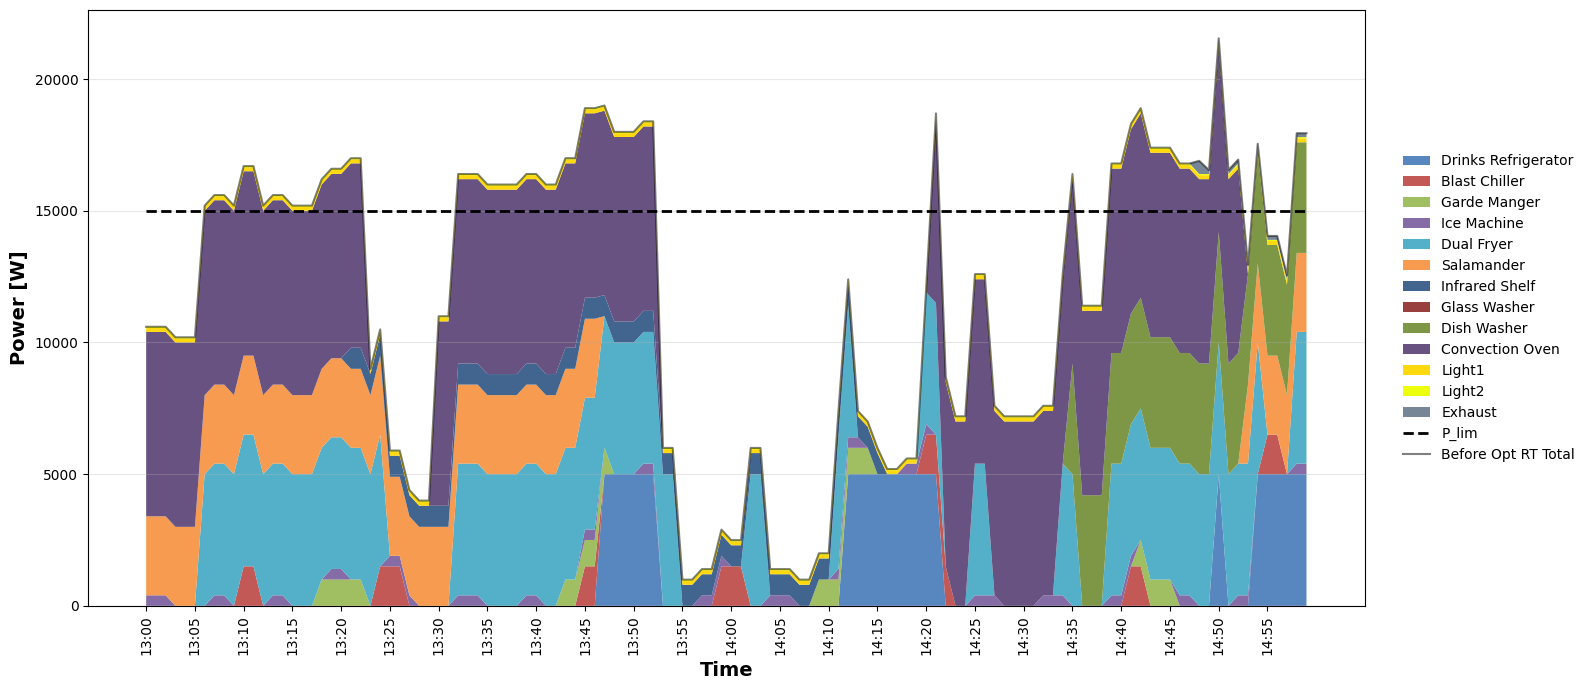

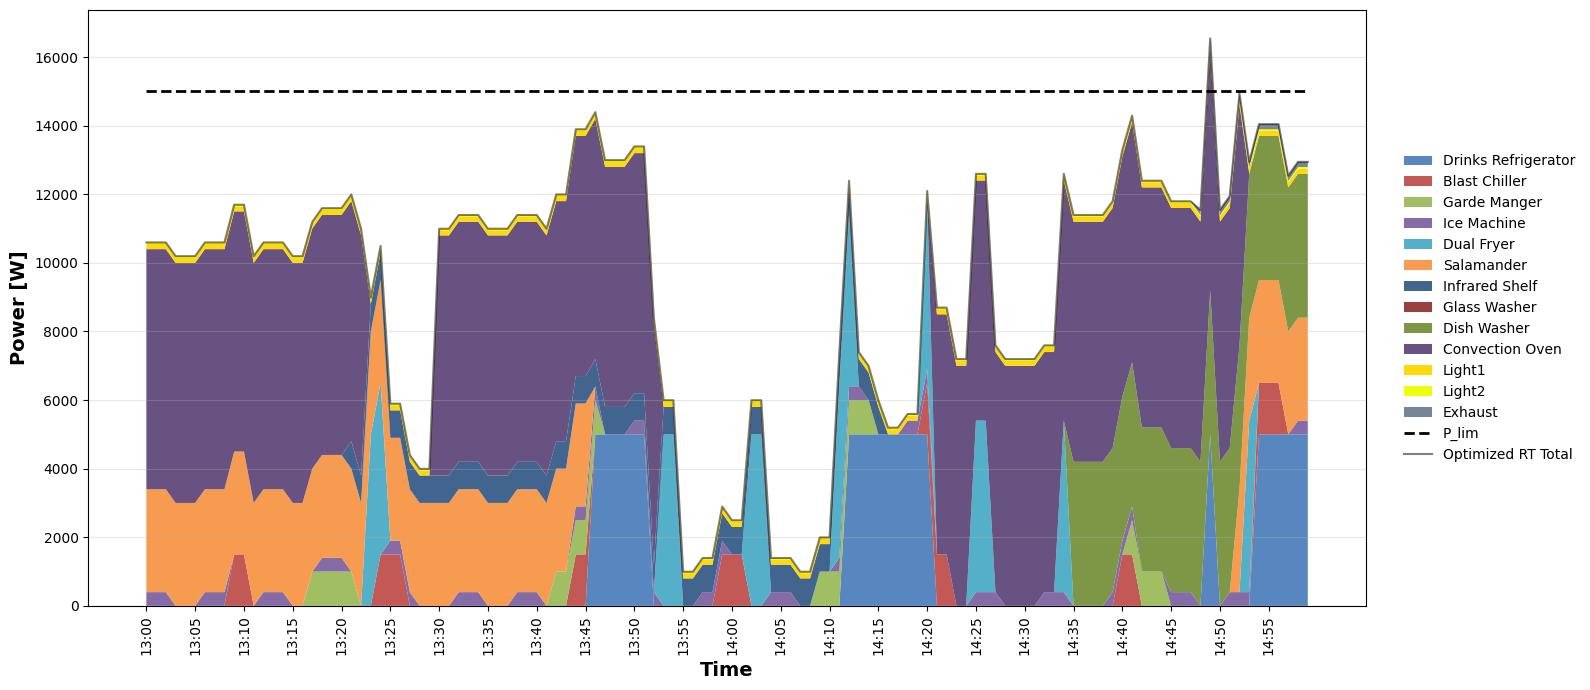


Metrics for interval 13:00 to 15:00


,case,energy_kWh,average_power_W,max_power_W
0,Baseline,24.710000,12355.000000,21550.0
1,Before Opt RT,23.537500,11768.750000,21545.0
2,Optimized RT,18.776667,9388.333333,16545.0



Peak / Threshold Violation Metrics for interval 13:00 to 15:00


,case,n_violations_min,violation_time_h,max_power_W,max_excess_W,mean_excess_when_violating_W,total_excess_kWh,violation_reduction_vs_baseline_%,excess_energy_reduction_vs_baseline_%,peak_power_reduction_vs_baseline_%
0,Baseline,41,0.683333,21550.0,6550.0,2450.000000,1.674167,0.000000,0.000000,0.000000
1,Before Opt RT,57,0.950000,21545.0,6545.0,1901.140351,1.806083,-39.024390,-7.879542,0.023202
2,Optimized RT,1,0.016667,16545.0,1545.0,1545.000000,0.025750,97.560976,98.461921,23.225058


In [53]:
tz_start = 13 * 60
tz_end = 15 * 60

for case_name, data in power_cases.items():
    plot_stacked_power_case(
        case_name=case_name,
        P_dev=data["P_dev"],
        P_total=data["P_total"],
        P_lim_vector=P_lim_vector,
        dev_names=dev_names,
        colors=colors,
        tz_start=tz_start,
        tz_end=tz_end,
        tick_step=5
    )
print(f"\nMetrics for interval {tz_start//60:02d}:{tz_start%60:02d} to {tz_end//60:02d}:{tz_end%60:02d}")
consumption_20_22_df = compute_consumption_metrics(
    power_cases,
    tz_start=tz_start,
    tz_end=tz_end
)

display(consumption_20_22_df)
print(f"\nPeak / Threshold Violation Metrics for interval {tz_start//60:02d}:{tz_start%60:02d} to {tz_end//60:02d}:{tz_end%60:02d}")
peak_20_22_df = compute_peak_metrics(
    power_cases,
    P_lim_vector,
    tz_start=tz_start,
    tz_end=tz_end
)

display(peak_20_22_df)

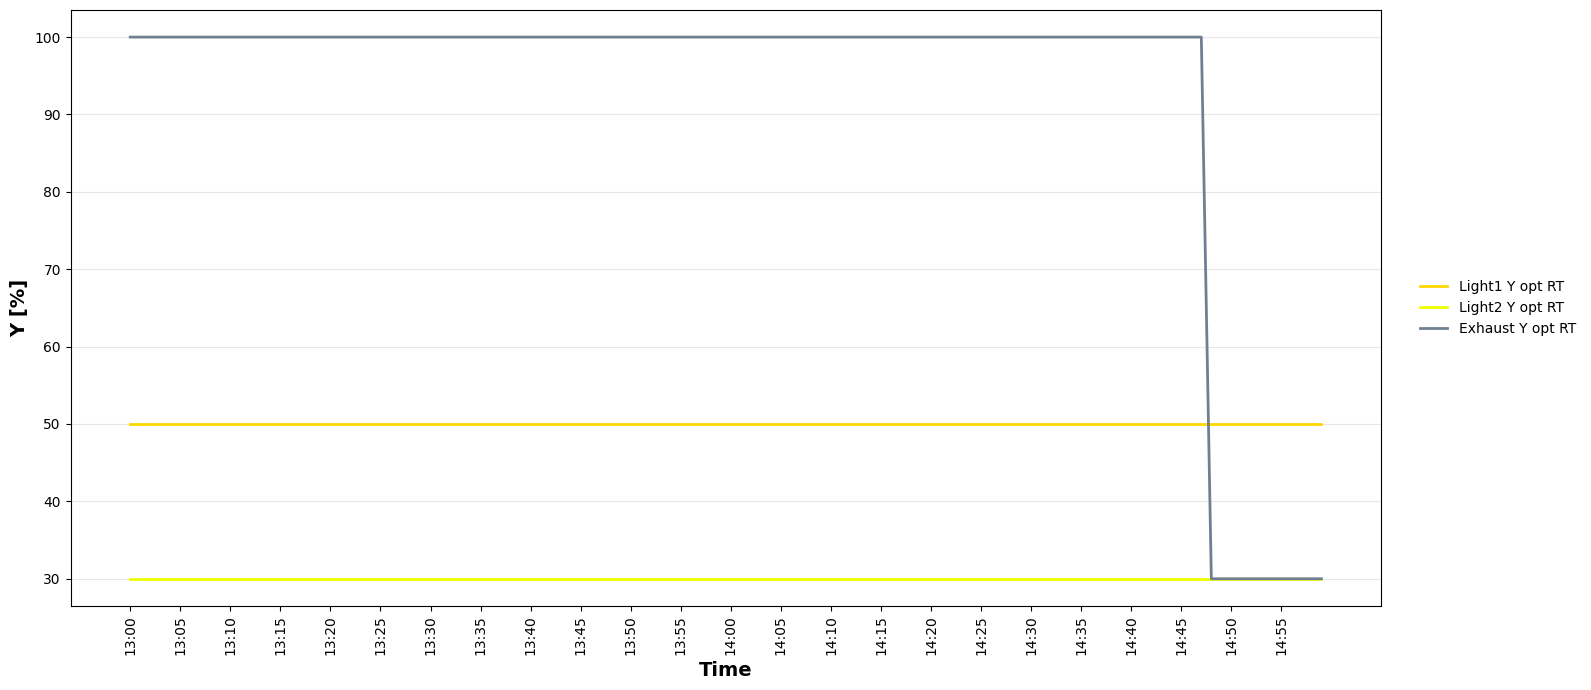

In [54]:
def plot_lights_y_wp(
    lights,
    Y_baseline_matrix,
    Y_before_opt_rt_matrix,
    Y_opt_rt_matrix,
    W_P_baseline_matrix,
    W_P_before_opt_rt_matrix,
    W_P_opt_rt_matrix,
    colors,
    dev_names,
    tz_start=0,
    tz_end=None,
    tick_step=5
):
    if tz_end is None:
        tz_end = Y_opt_rt_matrix.shape[0]

    _, time_labels = get_interval(tz_start, tz_end)

    # =========================
    # Y plot
    # =========================
    fig, ax = plt.subplots(figsize=(16, 7))

    for j in lights:
        ax.plot(
            range(len(time_labels)),
            Y_opt_rt_matrix[tz_start:tz_end, j]*100,
            lw=2,
            color=colors[j],
            label=f"{dev_names[j]} Y opt RT"
        )

    ax.set_ylabel("Y [%]", fontsize=14, fontweight="bold")
    ax.set_xlabel("Time", fontsize=14, fontweight="bold")
    ax.set_xticks(np.arange(0, len(time_labels), tick_step))
    ax.set_xticklabels(time_labels[::tick_step], rotation=90)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)

    plt.tight_layout()
    plt.show()
    
plot_lights_y_wp(
    lights=[10, 11, 12],
    Y_baseline_matrix=Y_baseline_matrix,
    Y_before_opt_rt_matrix=Y_before_opt_rt_matrix,
    Y_opt_rt_matrix=Y_opt_rt_matrix,
    W_P_baseline_matrix=W_P_baseline_matrix,
    W_P_before_opt_rt_matrix=W_P_before_opt_rt_matrix,
    W_P_opt_rt_matrix=W_P_opt_rt_matrix,
    colors=colors,
    dev_names=dev_names,
    tz_start=13 * 60,
    tz_end=15 * 60,
    tick_step=5
)

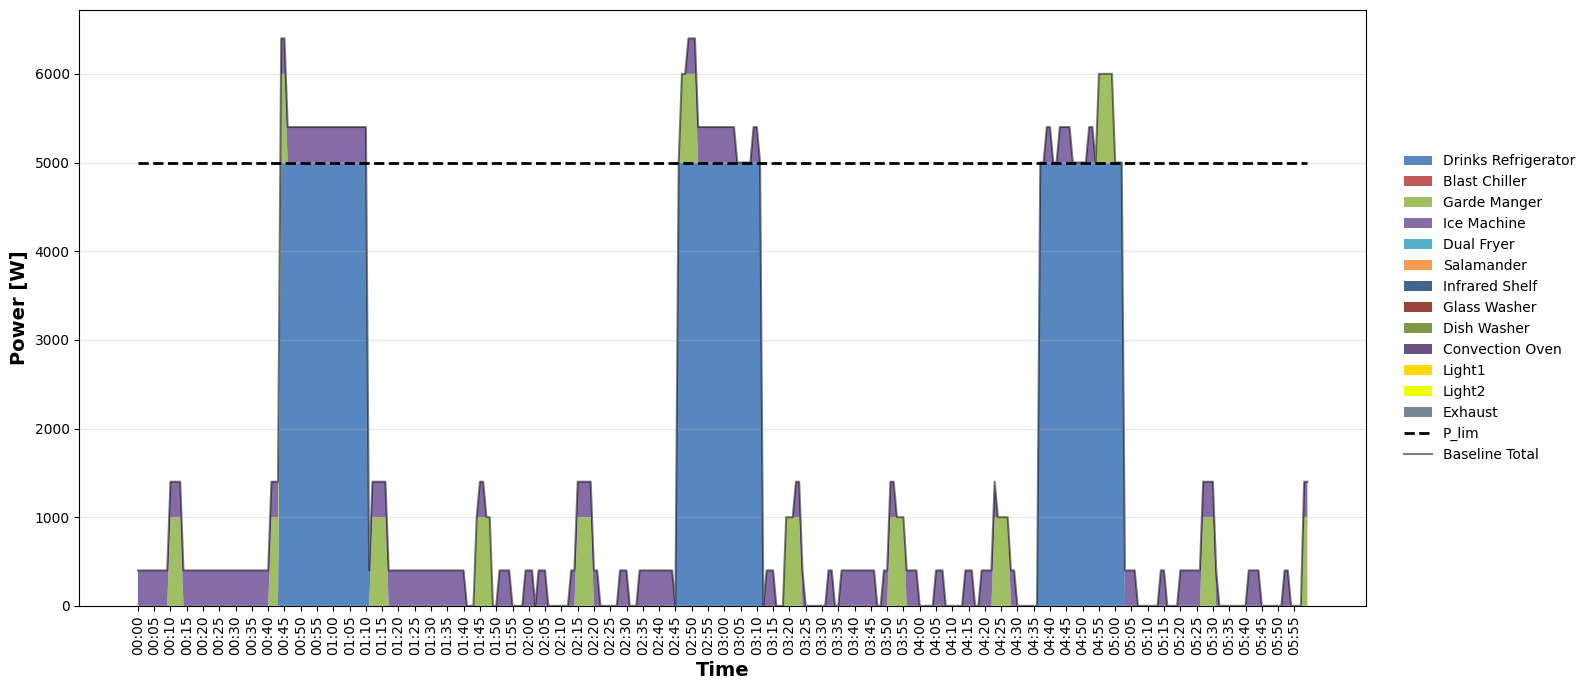

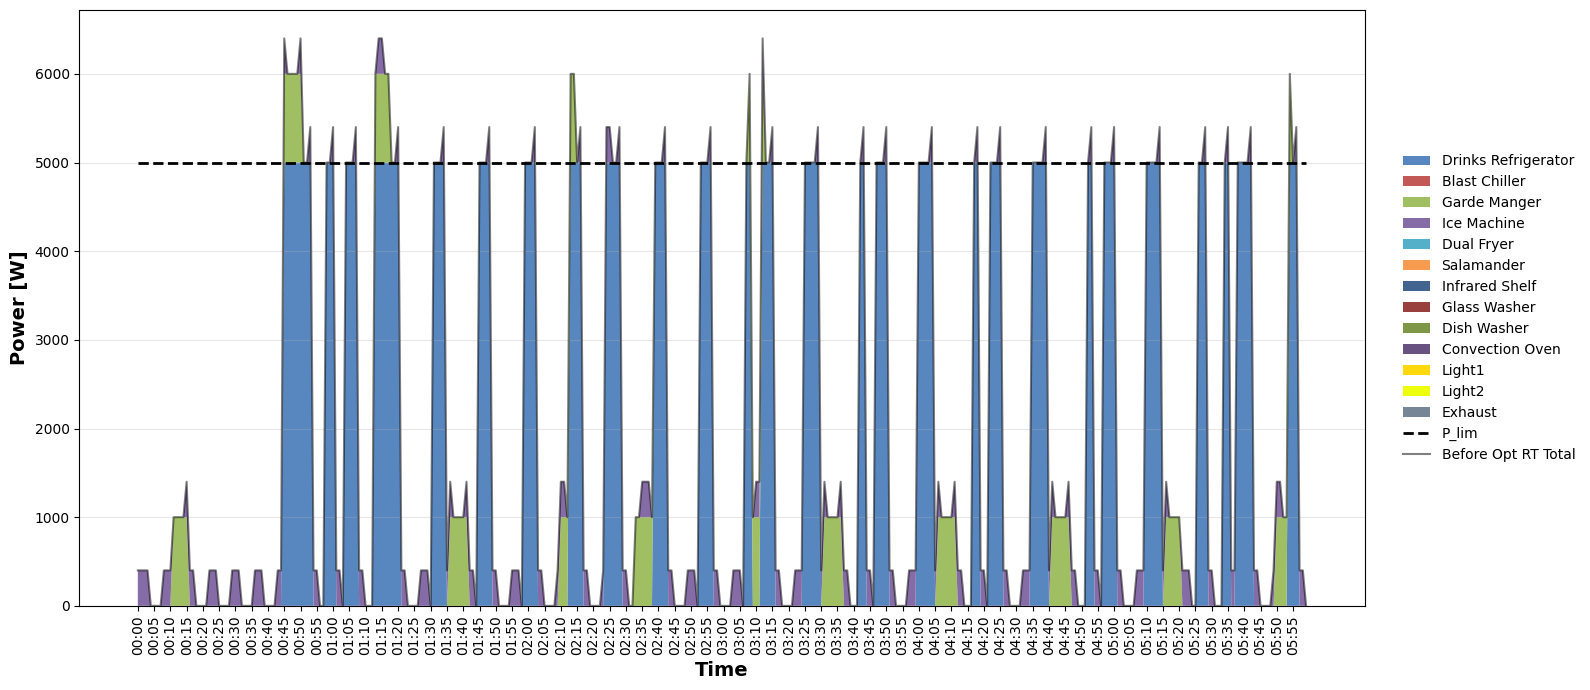

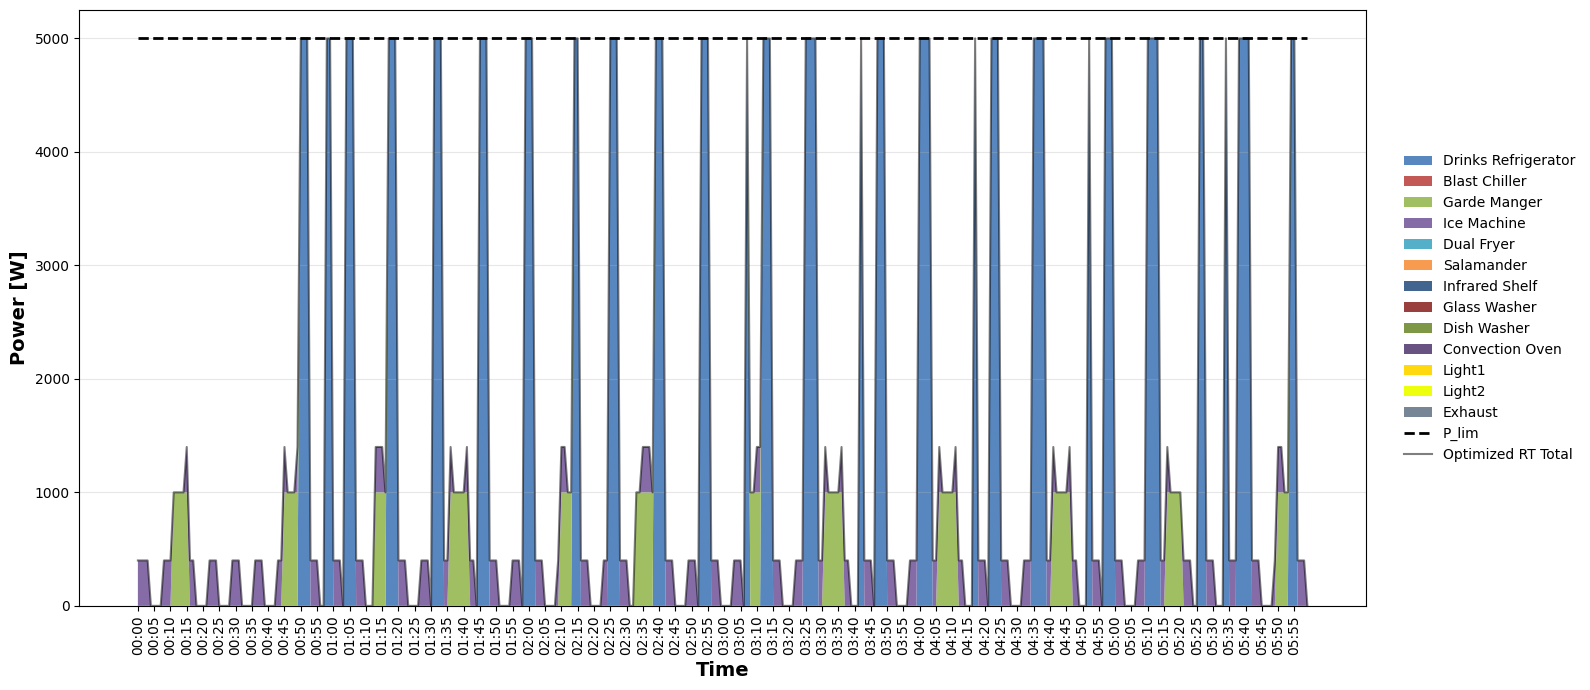


Energy Consumption Metrics for interval 00:00 to 06:00:


,case,energy_kWh,average_power_W,max_power_W
0,Baseline,9.013333,1502.222222,6400.0
1,Before Opt RT,11.313333,1885.555556,6400.0
2,Optimized RT,8.056667,1342.777778,5000.0



Peak / Threshold Violation Metrics for interval 00:00 to 06:00


,case,n_violations_min,violation_time_h,max_power_W,max_excess_W,mean_excess_when_violating_W,total_excess_kWh,violation_reduction_vs_baseline_%,excess_energy_reduction_vs_baseline_%,peak_power_reduction_vs_baseline_%
0,Baseline,59,0.983333,6400.0,1400.0,555.932203,0.546667,0.000000,0.00000,0.000
1,Before Opt RT,44,0.733333,6400.0,1400.0,663.636364,0.486667,25.423729,10.97561,0.000
2,Optimized RT,0,0.000000,5000.0,0.0,0.000000,0.000000,100.000000,100.00000,21.875


In [55]:
tz_start = 0
tz_end = 6 * 60

for case_name, data in power_cases.items():
    plot_stacked_power_case(
        case_name=case_name,
        P_dev=data["P_dev"],
        P_total=data["P_total"],
        P_lim_vector=P_lim_vector,
        dev_names=dev_names,
        colors=colors,
        tz_start=tz_start,
        tz_end=tz_end,
        tick_step=5
    )

consumption_20_22_df = compute_consumption_metrics(
    power_cases,
    tz_start=tz_start,
    tz_end=tz_end
)
print(f"\nEnergy Consumption Metrics for interval {tz_start//60:02d}:{tz_start%60:02d} to {tz_end//60:02d}:{tz_end%60:02d}:")
display(consumption_20_22_df)


peak_20_22_df = compute_peak_metrics(
    power_cases,
    P_lim_vector,
    tz_start=tz_start,
    tz_end=tz_end
)
print(f"\nPeak / Threshold Violation Metrics for interval {tz_start//60:02d}:{tz_start%60:02d} to {tz_end//60:02d}:{tz_end%60:02d}")
display(peak_20_22_df)


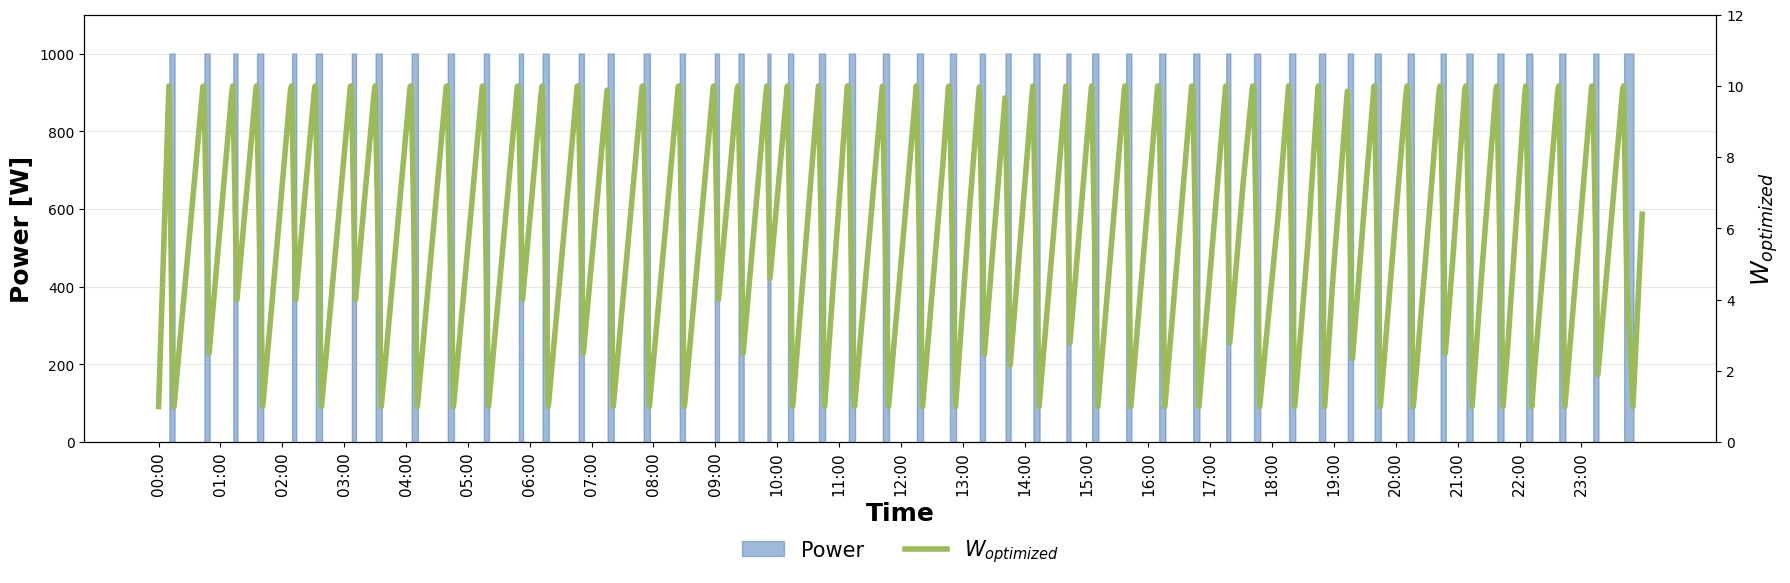

In [59]:
def plot_w_vs_power_device(
    device_idx,
    W_matrix,
    P_matrix,
    dev_names,
    label_W=r"$W_{optimized}$",
    title_suffix="Optimized",
    tz_start=0,
    tz_end=24*60,
    tick_step=60,
    save_path=None
):
    import numpy as np
    import matplotlib.pyplot as plt

    # =========================
    # TIME AXIS
    # =========================
    minutes = np.arange(tz_start, tz_end)

    labels = [f"{m//60:02d}:{m%60:02d}" for m in minutes]

    x = np.arange(len(minutes))

    # =========================
    # DATA
    # =========================
    W = W_matrix[tz_start:tz_end, device_idx]

    P = P_matrix[tz_start:tz_end, device_idx]

    # =========================
    # FIGURE
    # =========================
    fig, ax1 = plt.subplots(figsize=(18, 6))

    # =========================
    # POWER (LEFT AXIS)
    # =========================
    ax1.fill_between(
        x,
        P,
        step="mid",
        color="#4F81BD",
        alpha=0.55,
        label="Power"
    )

    ax1.set_xlabel(
        "Time",
        fontsize=18,
        fontweight="bold"
    )

    ax1.set_ylabel(
        "Power [W]",
        fontsize=18,
        fontweight="bold",
        color="black"
    )

    # Dynamic scaling
    ax1.set_ylim(0, max(P) * 1.1)

    ax1.tick_params(
        axis='y',
        labelcolor="black"
    )

    # =========================
    # WEIGHT (RIGHT AXIS)
    # =========================
    ax2 = ax1.twinx()

    ax2.plot(
        x,
        W,
        color="#9BBB59",
        linewidth=4,
        label=label_W
    )

    ax2.set_ylabel(
        label_W,
        fontsize=18,
        fontweight="bold",
        color="black"
    )

    ax2.set_ylim(0, 12)

    ax2.tick_params(
        axis='y',
        labelcolor="black"
    )

    # =========================
    # X TICKS
    # =========================
    ax1.set_xticks(
        np.arange(0, len(labels), tick_step)
    )

    ax1.set_xticklabels(
        labels[::tick_step],
        rotation=90,
        fontsize=11
    )

    # =========================
    # GRID
    # =========================
    ax1.grid(
        axis="y",
        alpha=0.3
    )

    # =========================
    # LEGEND
    # =========================
    lines1, labels1 = ax1.get_legend_handles_labels()

    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=2,
        frameon=False,
        fontsize=15
    )

    # =========================
    # NO TITLE
    # =========================

    plt.tight_layout()

    # =========================
    # SAVE
    # =========================
    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()


# ==========================================
# CALL FUNCTION
# ==========================================

plot_w_vs_power_device(
    device_idx=2,
    W_matrix=W_opt_rt_matrix,
    P_matrix=P_opt_rt_matrix,
    dev_names=dev_names,
    label_W=r"$W_{optimized}$",
    save_path="W_optimized_Power_Garde_Manger_24h.png"
)

In [57]:
from scipy.optimize import differential_evolution
import numpy as np

j = 0  # Drinks Refrigerator

X_base = X_baseline_matrix[:, j]
X_opt = X_opt_rt_matrix[:, j]

def plot_fridge_temperature_smartfridge(
    T_baseline,
    T_opt,
    X_baseline,
    X_opt,
    SP=4.0,
    H_minus=2.0,
    H_plus=6.0,
    tick_step=60,
    save_path=None
):
    import numpy as np
    import matplotlib.pyplot as plt

    # =========================
    # TIME AXIS
    # =========================
    n = len(T_opt)

    minutes = np.arange(n)
    labels = [f"{m//60:02d}:{m%60:02d}" for m in minutes]

    x = np.arange(n)

    # =========================
    # FIGURE
    # =========================
    fig, ax1 = plt.subplots(figsize=(18, 6))

    # =========================
    # TEMPERATURE (LEFT AXIS)
    # =========================
    ax1.plot(
        x,
        T_baseline,
        linewidth=3,
        color="#4F81BD",   # baseline blue
        label="Temperature baseline"
    )

    ax1.plot(
        x,
        T_opt,
        linewidth=3,
        color="#F79646",   # optimized orange
        label="Temperature optimized"
    )

    # =========================
    # SETPOINT AND LIMITS
    # =========================
    ax1.axhline(
        SP,
        linestyle=":",
        linewidth=2.5,
        color="black",
        label="Setpoint"
    )

    ax1.axhline(
        H_minus,
        linestyle="--",
        linewidth=2,
        color="gray",
        label="H- lower limit"
    )

    ax1.axhline(
        H_plus,
        linestyle="--",
        linewidth=2,
        color="gray",
        label="H+ upper limit"
    )

    # =========================
    # AXIS LABELS
    # =========================
    ax1.set_xlabel(
        "Time",
        fontsize=18,
        fontweight="bold"
    )

    ax1.set_ylabel(
        "Temperature [°C]",
        fontsize=18,
        fontweight="bold",
        color="black"
    )

    ax1.tick_params(
        axis='y',
        labelcolor="black"
    )

    # =========================
    # X TICKS
    # =========================
    ax1.set_xticks(
        np.arange(0, len(labels), tick_step)
    )

    ax1.set_xticklabels(
        labels[::tick_step],
        rotation=90,
        fontsize=11
    )

    # =========================
    # GRID
    # =========================
    ax1.grid(
        axis="y",
        alpha=0.3
    )

    # =========================
    # COMPRESSOR STATUS (RIGHT AXIS)
    # =========================
    ax2 = ax1.twinx()

    ax2.step(
        x,
        X_baseline,
        where="post",
        linewidth=3,
        color="#4F81BD",
        alpha=0.30,
        label="X baseline"
    )

    ax2.step(
        x,
        X_opt,
        where="post",
        linewidth=3,
        color="#F79646",
        alpha=0.30,
        label="X optimized"
    )

    ax2.set_ylabel(
        "Compressor Status",
        fontsize=18,
        fontweight="bold",
        color="black"
    )

    ax2.set_ylim(-0.1, 1.1)

    ax2.set_yticks([0, 1])

    ax2.tick_params(
        axis='y',
        labelcolor="black"
    )

    # =========================
    # LEGEND
    # =========================
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=3,
        frameon=False,
        fontsize=14
    )

    # =========================
    # NO TITLE
    # =========================

    plt.tight_layout()

    # =========================
    # SAVE
    # =========================
    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()


# ==========================================
# CALL FUNCTION
# ==========================================

j = 0  # Drinks Refrigerator

X_base = X_baseline_matrix[:, j]
X_opt = X_opt_rt_matrix[:, j]

def reconstruct_fridge_temperature_smartfridge(
    X, T0=4.0, P=60, mc=20, A=3.21, eta=3.0, Tamb=18.0, dt_minutes=1
):
    X = np.asarray(X).astype(int)
    T = np.zeros(len(X))
    T[0] = T0

    dt_hours = dt_minutes / 60
    epsilon = np.exp(-(dt_hours * A) / mc)

    for i in range(len(X) - 1):
        T[i + 1] = (
            epsilon * (T[i] - Tamb)
            + Tamb
            - eta * (P / A) * (1 - epsilon) * X[i]
        )

    return T


def tune_smartfridge_parameters(
    X_base,
    H_minus=2.0,
    H_plus=6.0,
    T0=4.0,
    dt_minutes=1
):
    SP = (H_minus + H_plus) / 2
    target_amp = (H_plus - H_minus) / 2

    def objective(params):
        P, mc, A, eta, Tamb = params

        T = reconstruct_fridge_temperature_smartfridge(
            X_base,
            T0=T0,
            P=P,
            mc=mc,
            A=A,
            eta=eta,
            Tamb=Tamb,
            dt_minutes=dt_minutes
        )

        upper_violation = np.maximum(T - H_plus, 0)
        lower_violation = np.maximum(H_minus - T, 0)

        violation_penalty = 1000 * (
            np.mean(upper_violation**2) +
            np.mean(lower_violation**2)
        )

        center_penalty = np.mean((np.mean(T) - SP) ** 2)
        amplitude_penalty = (np.std(T) - target_amp / 2) ** 2

        # Evita soluções artificiais demasiado lisas ou demasiado explosivas
        smoothness_penalty = 0.01 * np.mean(np.diff(T) ** 2)

        return violation_penalty + center_penalty + amplitude_penalty + smoothness_penalty

    bounds = [
    (50, 300),       # P [W]
    (8, 300),        # mc [Wh/K]
    (3.21, 3.21),    # A fixo
    (3.0, 3.0),      # eta fixo
    (18, 23)         # Tamb
    ]

    result = differential_evolution(
        objective,
        bounds=bounds,
        seed=42,
        maxiter=300,
        polish=True
    )

    P, mc, A, eta, Tamb = result.x

    return {
        "P": P,
        "mc": mc,
        "A": A,
        "eta": eta,
        "Tamb": Tamb,
        "loss": result.fun
    }
    
best_params = tune_smartfridge_parameters(
    X_base,
    H_minus=2.0,
    H_plus=6.0,
    T0=4.0,
    dt_minutes=1
)

best_params

{'P': np.float64(60.96847577527813),
 'mc': np.float64(26.532835218004724),
 'A': np.float64(3.21),
 'eta': np.float64(3.0),
 'Tamb': np.float64(18.0),
 'loss': 0.011011497001308043}

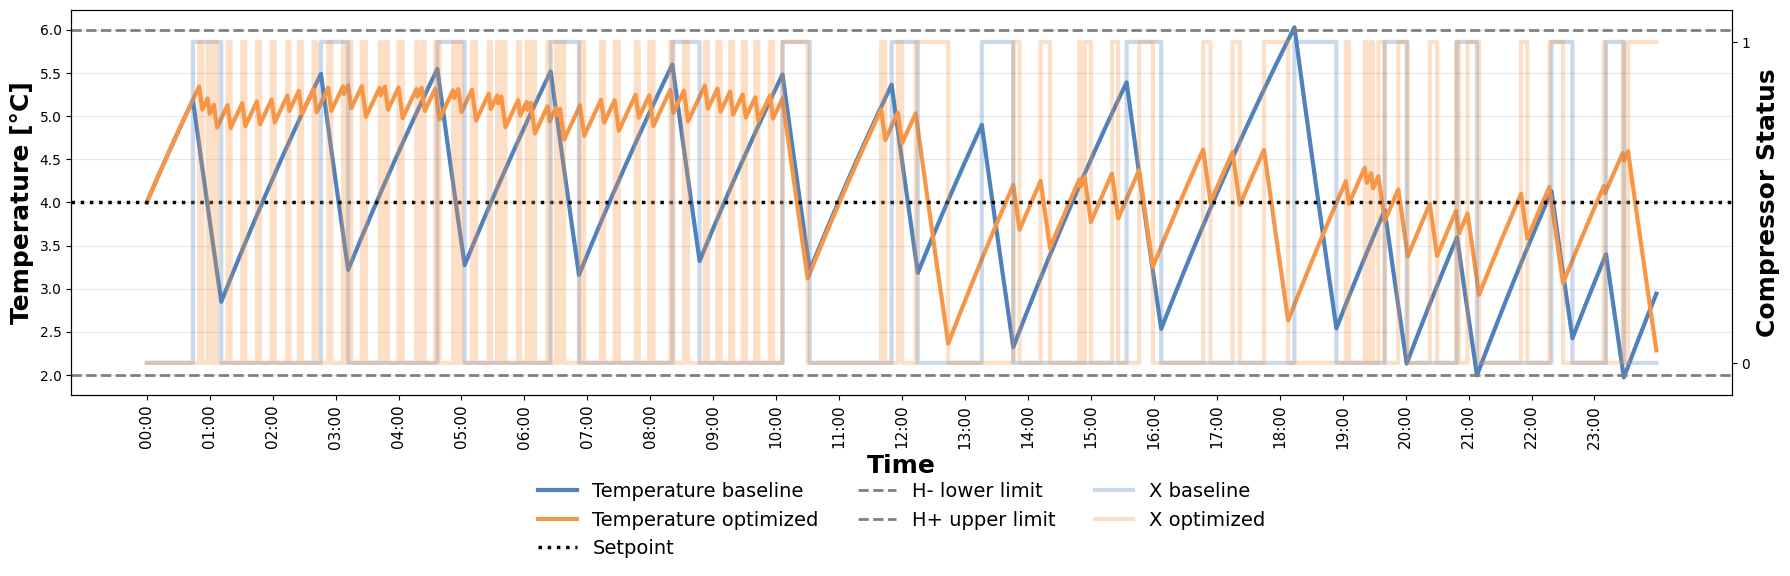

In [60]:
# ==========================================
# RECONSTRUCT TEMPERATURES
# ==========================================

T_baseline = reconstruct_fridge_temperature_smartfridge(
    X_base,
    T0=4.0,
    P=best_params["P"],
    mc=best_params["mc"],
    A=best_params["A"],
    eta=best_params["eta"],
    Tamb=best_params["Tamb"],
    dt_minutes=1
)

T_opt = reconstruct_fridge_temperature_smartfridge(
    X_opt,
    T0=4.0,
    P=best_params["P"],
    mc=best_params["mc"],
    A=best_params["A"],
    eta=best_params["eta"],
    Tamb=best_params["Tamb"],
    dt_minutes=1
)

# ==========================================
# PLOT
# ==========================================

plot_fridge_temperature_smartfridge(
    T_baseline=T_baseline,
    T_opt=T_opt,
    X_baseline=X_base,
    X_opt=X_opt,
    SP=4.0,
    H_minus=2.0,
    H_plus=6.0,     
    tick_step=60
)